# NILE compared with the state of the art

This notebook runs the empirical comparisons described in the thesis section
*NILE comparison to the state of the art tools*. It is the companion of
`Benchmarks.ipynb`, whose outputs it reads rather than recomputes: the SPHINX
profiles, RIDDLE's ground truth and per-query results, and SCARAB's per-query
results. Each comparison therefore sets another tool against exactly the
figures reported for NILE's own evaluation.

**Structure.** After the environment and a shared configuration (parts 1 and
2), the notebook follows the four subsections of the thesis:

* **Part 3, SPHINX.** SPHINX, sheXer and QSE extract shapes from the SPARQL
  endpoint of every dataset, and the time each takes and the shapes it produces
  are measured. The CARE-SM profiles are reduced to (A, P, B) triples with
  RIDDLE's own reader and compared.
* **Part 4, RIDDLE.** RIDDLE's source selection over the LargeRDFBench simple
  queries is set against FedX, CostFed and DeTrusty, run over the same SPARQL
  endpoints. RIDDLE is then run over the profiles sheXer and QSE produced in
  part 3.
* **Part 5, SCARAB.** SCARAB is set against Comunica over the same QPF
  interfaces, for every benchmark query.
* **Part 6, NILE.** NILE end to end is set against FedX, CostFed and DeTrusty
  over the LargeRDFBench SPARQL endpoints, with reference answers from a single
  store holding the union of the six datasets.

**What is not measured.** Each figure is taken from what the tool itself
records; no proxy sits between the tools and the repositories. The number of
requests a tool sends is therefore reported only where the tool counts them:
Comunica (its own HTTP counter), CostFed (the remote ASK checks its source
selection issues) and SCARAB (the instrumentation of `Benchmarks.ipynb`). For
FedX the ASK requests of a cold-cache source selection are given analytically,
one per triple pattern and endpoint, and RIDDLE and DeTrusty issue none by
design. Requests issued while building indexes are not reported.

**Requirements.** `Benchmarks.ipynb` must have been run to completion in the
directory named by `BENCHMARK_DIR`. The tools must be installed as described
in `SETUP.md`, and every endpoint, QPF server and the local store must be
running.

**Outputs.** Every table is written as a CSV file to `OUT_DIR`; per-run logs
and scratch files go to `WORK_DIR`. The file written by each cell is named in
the cell's description.

**Methodology.** As in `Benchmarks.ipynb`, every measured run is repeated
`REPEATS` times, the first repetition is treated as a warm-up of the QLever
caches when `DISCARD_FIRST` is set, and the mean and standard deviation of the
rest are reported. Every run of an external tool happens in a separate
process with a timeout, so that no state carries over between runs and a run
that does not finish is recorded as such instead of blocking the notebook.

## 1. Execution environment

The date, the Python packages and the versions of the external tools are
recorded, since the measurements depend on all of them and none is captured by
the code itself. The external tools are queried once their paths are
configured, at the end of part 2.1.

In [1]:
import datetime
import platform
import sys
from importlib import metadata

print(datetime.datetime.now())
print("Python", sys.version.split()[0], "on", platform.platform())
for package in ("nile-query-suite", "rdflib", "shexer", "DeTrusty", "pandas", "requests"):
    try:
        print(f"  {package} {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"  {package}: not installed")

2026-10-15 15:57:00.449681
Python 3.12.3 on Linux-7.0.0-38-generic-x86_64-with-glibc2.39
  nile-query-suite 0.1.0
  rdflib 7.1.4
  shexer 2.7.3.1
  DeTrusty 0.25.0
  pandas 2.2.3
  requests 2.34.2


## 2. Shared configuration and helpers

### 2.1 Configuration

The endpoint labels and benchmark definitions are the same as in
`Benchmarks.ipynb`, so that rows of the two notebooks can be joined on them.
`LRB_UNION_ENDPOINT` is the QLever instance holding the union of the six
LargeRDFBench datasets. It provides the reference answers to the
LargeRDFBench queries, which span several repositories and therefore cannot
be answered by any one of them.

Paths to the external tools follow the layout of `SETUP.md`. Two JDKs are
used: CostFed and FedX are built against RDF4J 2.3.2 and target Java 8, while
QSE needs Java 11 or newer.

**Queries, references and SCARAB's settings are those of `Benchmarks.ipynb`.**
The queries are read from its prepared copy (`Queries/prepared`: BSBM
instantiated, WatDiv constants repaired), so that rows of the two notebooks
refer to the same query texts. Reference answers are computed as there: with
Oxigraph over the dataset files listed in `REFERENCE_FILES`, and otherwise by
the reference endpoint. SCARAB is configured with the settings
`Benchmarks.ipynb` recorded in `scarab_settings.json`. `SCARAB_BENCHMARKS`
are the benchmarks SCARAB was evaluated on alone there; LargeRDFBench was only
evaluated with the complete workflow, which part 6 reproduces here.

The timeouts are wall-clock limits on one run. **`MEMORY_LIMIT_GB`** limits the
memory of one run, every process it starts included (60% of the machine's
memory by default). A run exceeding it is killed and recorded as `memory limit
exceeded`: an engine holding a large intermediate result in memory would
otherwise exhaust the VM, which then stops responding before any timeout can
fire. The Java engines' heaps (`-Xmx`) stay below the limit, so it only acts on
memory they use outside their heap. `ENGINE_TIMEOUT` is the
timeout reported in the thesis for the federated engines and Comunica, and it
equals the `HARVEST_TIMEOUT` used for SCARAB in `Benchmarks.ipynb`, so that
all systems in parts 5 and 6 are given the same time.

In [8]:
# ------------------------------------------------------
# Configuration
# ------------------------------------------------------
import os
from pathlib import Path

# Where Benchmarks.ipynb was run and left its outputs.
BENCHMARK_DIR = Path(".")
PROFILE_DIR = BENCHMARK_DIR / "Profiles"
# The prepared queries of Benchmarks.ipynb (not the distributed ones: those
# include BSBM templates and WatDiv constants that do not exist in the data).
QUERY_DIR = BENCHMARK_DIR / "Queries" / "prepared"

# Outputs of this notebook, and scratch space for individual runs.
OUT_DIR = Path("./comparison_results")
WORK_DIR = Path("./comparison_work")

# Same labels and endpoints as in Benchmarks.ipynb.
endpoints = {
    "lmdb": "http://acb8computer:7019",
    "Care-SM": "http://acb8computer:7020",
    "Berlin": "http://acb8computer:7021",
    "Chebi": "http://acb8computer:7022",
    "dbpedia": "http://acb8computer:7023",
    "drugbank": "http://acb8computer:7024",
    "kegg": "http://acb8computer:7025",
    "nyt": "http://acb8computer:7026",
    "sp2bench": "http://acb8computer:7027",
    "watdiv": "http://acb8computer:7028",
}
BENCHMARKS = {
    "sp2bench": ["sp2bench"],
    "watdiv": ["watdiv"],
    "berlin": ["Berlin"],
    "LargeRDFBench": ["Chebi", "dbpedia", "drugbank", "kegg", "lmdb", "nyt"],
}
LRB = "LargeRDFBench"
LRB_LABELS = BENCHMARKS[LRB]

# QLever instance holding the union of the six LargeRDFBench datasets.
LRB_UNION_ENDPOINT = "http://acb8computer:7029"

# Benchmarks SCARAB was evaluated on alone in Benchmarks.ipynb (part 4).
SCARAB_BENCHMARKS = ["sp2bench", "watdiv", "berlin"]

# Reference answers computed with Oxigraph over these files, as in
# Benchmarks.ipynb (same paths as its REFERENCE_FILES); None: use the endpoint.
REFERENCE_FILES = {
    "sp2bench": None,   # e.g. "./Data/sp2bench/sp2b_50k.n3"
    "berlin": None,     # e.g. "./Data/bsbm/dataset.nt"
}

# Default: 60% of the machine's memory, but never more than what is free now
# less 2 GB, since QLever, the QPF server and this kernel need memory too.
with open("/proc/meminfo") as _f:
    _meminfo = {l.split(":")[0]: int(l.split()[1]) / 2**20 for l in _f}
_MEM_TOTAL_GB, _MEM_AVAILABLE_GB = _meminfo["MemTotal"], _meminfo["MemAvailable"]
MEMORY_LIMIT_GB = round(max(1.0, min(0.6 * _MEM_TOTAL_GB, _MEM_AVAILABLE_GB - 2)), 1)

# Have the kernel enforce MEMORY_LIMIT_GB on every external tool (Comunica,
# QSE, FedX, CostFed), with no swap, where systemd allows it (checked in 2.2).
# The once-a-second watchdog stays on as well, and is the only guard for the
# tools run inside forked Python processes (SPHINX, sheXer, DeTrusty, SCARAB).
HARD_MEMORY_LIMIT = True

# SCARAB's settings, as recorded by Benchmarks.ipynb.
SCARAB_SETTINGS_FILE = BENCHMARK_DIR / "scarab_settings.json"

# External tools (see SETUP.md).
TOOLS_DIR = Path.home() / "comparison-tools"
JAVA8 = Path("/usr/lib/jvm/java-8-openjdk-amd64/bin/java")
JAVA17 = Path("/usr/lib/jvm/java-17-openjdk-amd64/bin/java")
COSTFED_DIR = TOOLS_DIR / "CostFed"
COSTFED_JAR = COSTFED_DIR / "costfed" / "target" / "costfed-core-0.0.1-SNAPSHOT.jar"
DRIVER_DIR = TOOLS_DIR / "drivers"          # holds NileComparisonDriver.class
QSE_DIR = TOOLS_DIR / "qse"
QSE_JAR = QSE_DIR / "jar" / "qse.jar"
# Lets QSE query a plain SPARQL endpoint (see part 3 and SETUP.md).
QSE_ADAPTER_DIR = TOOLS_DIR / "qse-sparql-adapter"
NODE = Path("/usr/bin/node")
COMUNICA = TOOLS_DIR / "comunica" / "node_modules" / ".bin" / "comunica-sparql"

# Repetitions, and whether the first is a warm-up (as in Benchmarks.ipynb).
REPEATS = 2
DISCARD_FIRST = False

# Wall-clock limits, in seconds.
ENGINE_TIMEOUT = 1800          # federated engines, Comunica; = HARVEST_TIMEOUT
EXTRACTOR_TIMEOUT =  3600      # one shape extraction
INDEX_TIMEOUT = 24 * 3600      # building the CostFed index or DeTrusty's RDF-MTs
REFERENCE_TIMEOUT = 600        # fetching one reference answer

# Memory given to the JVMs and to Node.
ENGINE_XMX = "7g"
QSE_XMX = "7g"
# Node's heap must stay below the per-run limit, so that Comunica fails with
# its own out-of-memory error instead of growing until the VM swaps.
NODE_MAX_OLD_SPACE_MB = int(0.75 * MEMORY_LIMIT_GB * 1024)

OUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Everything the notebook reads must exist before anything is run.
required = {
    "profile directory": PROFILE_DIR,
    "query directory": QUERY_DIR,
    "profile_benchmarks.csv": BENCHMARK_DIR / "profile_benchmarks.csv",
    "profile_runs.csv": BENCHMARK_DIR / "profile_runs.csv",
    "riddle_patterns.csv": BENCHMARK_DIR / "riddle_patterns.csv",
    "riddle_queries.csv": BENCHMARK_DIR / "riddle_queries.csv",
    "scarab_queries.csv": BENCHMARK_DIR / "scarab_queries.csv",
    "scarab_settings.json": SCARAB_SETTINGS_FILE,
    "benchmark_queries.py": BENCHMARK_DIR / "benchmark_queries.py",
    "Java 8": JAVA8,
    "Java 17": JAVA17,
    "CostFed jar": COSTFED_JAR,
    "compiled driver": DRIVER_DIR / "NileComparisonDriver.class",
    "QSE jar": QSE_JAR,
    "QSE SPARQL adapter": QSE_ADAPTER_DIR / "cs" / "utils" / "graphdb" / "KBManagement.class",
    "QSE resources": QSE_DIR / "src" / "main" / "resources" / "queries",
    "Node.js": NODE,
    "Comunica": COMUNICA,
}
missing = [f"{name}: {path}" for name, path in required.items() if not Path(path).exists()]
missing += [f"reference file for {b}: {p}" for b, p in REFERENCE_FILES.items()
            if p and not Path(p).exists()]
if missing:
    raise RuntimeError("Missing inputs:\n  " + "\n  ".join(missing))

import json as _json
import sys as _sys
SCARAB_SETTINGS = {k: v for k, v in _json.loads(SCARAB_SETTINGS_FILE.read_text()).items()
                   if k != "export_harvests"}
_sys.path.insert(0, str(BENCHMARK_DIR.resolve()))   # benchmark_queries
print("Configuration complete. SCARAB settings:", SCARAB_SETTINGS)
print(f"Memory limit per run: {MEMORY_LIMIT_GB} GB "
      f"({_MEM_AVAILABLE_GB:.1f} GB free of {_MEM_TOTAL_GB:.1f} GB); Node heap {NODE_MAX_OLD_SPACE_MB} MB")

# A JVM uses its heap plus roughly 2 GB outside it. A heap that does not fit
# under the limit would get well-behaved Java runs killed by the watchdog.
def _gigabytes(size):
    size = str(size).strip().lower()
    return float(size[:-1]) / (1024 if size.endswith("m") else 1) if size[-1] in "gm" else float(size) / 2**30
for _name, _xmx in (("ENGINE_XMX", ENGINE_XMX), ("QSE_XMX", QSE_XMX)):
    if _gigabytes(_xmx) + 2 > MEMORY_LIMIT_GB:
        print(f"Warning: {_name} = {_xmx} does not fit under MEMORY_LIMIT_GB = {MEMORY_LIMIT_GB} "
              f"(heap + about 2 GB). Lower {_name} to {max(1, int(MEMORY_LIMIT_GB - 2))}g, or raise "
              f"MEMORY_LIMIT_GB if the machine can afford it, and report the value used.")

Configuration complete. SCARAB settings: {'max_threads': 16, 'parallel_sources': 4, 'full_page_weight': 1.0, 'sparql_values_block': 100, 'working_store_dir': None}
Memory limit per run: 6.0 GB (8.0 GB free of 15.6 GB); Node heap 4608 MB


In [3]:
# ------------------------------------------------------
# Versions of the external tools
# ------------------------------------------------------
import hashlib
import json
import subprocess


def command_output(cmd):
    """First lines of a command's combined output, or the error."""
    try:
        done = subprocess.run([str(c) for c in cmd], capture_output=True, text=True, timeout=120)
        return (done.stdout + done.stderr).strip().splitlines()[:2]
    except Exception as exc:
        return [f"{type(exc).__name__}: {exc}"]


def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def comunica_versions():
    """The installed @comunica/query-sparql package, and the engine version.

    `comunica-sparql --version` prints a table to standard error and exits
    with status 1, so the engine row is picked out of both streams; the
    package version, which is what was installed, is read from the package
    itself.
    """
    package_json = COMUNICA.resolve().parents[1] / "package.json"   # .../@comunica/query-sparql
    if not package_json.exists():
        package_json = COMUNICA.parent.parent / "@comunica" / "query-sparql" / "package.json"
    package = json.loads(package_json.read_text())["version"] if package_json.exists() else None
    try:
        done = subprocess.run([str(NODE), str(COMUNICA), "--version"],
                              capture_output=True, text=True, timeout=120)
        rows = [[cell.strip() for cell in line.strip().strip("|").split("|")]
                for line in (done.stdout + done.stderr).splitlines() if line.strip().startswith("|")]
        engine = next((row[1] for row in rows if row and row[0] == "Comunica Engine"), None)
    except Exception as exc:
        engine = f"{type(exc).__name__}: {exc}"
    return {"@comunica/query-sparql": package, "Comunica Engine": engine}


print("Java 8: ", command_output([JAVA8, "-version"]))
print("Java 17:", command_output([JAVA17, "-version"]))
print("Node:   ", command_output([NODE, "--version"]))
print("Comunica:", comunica_versions())
print("CostFed commit:", command_output(["git", "-C", COSTFED_DIR, "rev-parse", "HEAD"]))
print("QSE commit:    ", command_output(["git", "-C", QSE_DIR, "rev-parse", "HEAD"]))
print("qse.jar sha256:", sha256(QSE_JAR))

Java 8:  ['openjdk version "1.8.0_504"', 'OpenJDK Runtime Environment (build 1.8.0_504-8u504-ga-1ubuntu1~24.04.3-b01)']
Java 17: ['openjdk version "17.0.20.1" 2026-08-18', 'OpenJDK Runtime Environment (build 17.0.20.1+1-1-24.04-Ubuntu)']
Node:    ['v22.23.3']
Comunica: {'@comunica/query-sparql': '5.4.1', 'Comunica Engine': '5.4.0'}
CostFed commit: ['5855c6b78b22476d915f7a1a77b1b046445b2cab']
QSE commit:     ['4bcfb04a30c27fe3e802413b73e00e08033da2b7']
qse.jar sha256: 1710693cc4f34075ac76f473d83059b630734f6cb9118dba7f94b13a75325632


### 2.2 Shared helpers

**Queries.** Every benchmark query is loaded once. `query_features` records
the form of a query (`SELECT` or `ASK`) and whether it carries a `LIMIT`,
since Comunica can stop retrieving early for such queries and SCARAB cannot.

**Answers.** Answers from different systems are compared exactly as in
`Benchmarks.ipynb` (part 4.2): terms are normalised (blank nodes to one
placeholder, numeric literals by value, `xsd:string` as plain literals,
language tags case-insensitively), a `SELECT` answer becomes a multiset of
solutions and an `ASK` answer a boolean, and `compare` computes completeness
and soundness under bag and set semantics.

`read_results_file` reads an answer written to disk by another system. Both
the CostFed/FedX driver and Comunica write one solution per line, so when a
run was cut short by its timeout the solutions received until then can still
be read: the answer is then returned together with `complete = False`.

**Processes.** `run_process` runs an external command with a timeout, killing
its whole process group when the timeout is reached, since both the JVM
engines and DeTrusty start processes of their own. `run_in_child` runs a
Python function in a forked process for the same reasons: isolation of
module-level state (SCARAB, DeTrusty), memory (sheXer) and a timeout.

In [4]:
# ------------------------------------------------------
# Shared helpers
# ------------------------------------------------------
import contextlib
import io
import json
import logging
import multiprocessing
import re
import shutil
import signal
import subprocess
import sys
import time
import uuid
from collections import Counter
from decimal import Decimal, InvalidOperation

import pandas as pd
import requests
from rdflib.plugins.sparql.algebra import translateQuery
from rdflib.plugins.sparql.parser import parseQuery
from rdflib.plugins.sparql.parserutils import CompValue

logging.getLogger("rdflib.term").setLevel(logging.ERROR)

RDF_TYPE = "http://www.w3.org/1999/02/22-rdf-syntax-ns#type"
TYPE_TERM = f"<{RDF_TYPE}>"          # rdf:type as it appears in a SPARQL pattern


def ratio(num, den):
    return num / den if den else float("nan")


def as_bool(series):
    """Booleans read back from CSV, where NaN marks an unknown value."""
    return series.map({True: True, False: False, "True": True, "False": False})


# --- Queries ---------------------------------------------------------------

queries = {}
for benchmark in BENCHMARKS:
    for path in sorted(Path(QUERY_DIR, benchmark).glob("*.sparql")):
        queries[(benchmark, path.stem)] = path.resolve()


def query_features(text):
    """Form of a query and whether it has a LIMIT anywhere."""
    algebra = translateQuery(parseQuery(text)).algebra
    names, seen = set(), set()

    def walk(node):
        if id(node) in seen:
            return
        seen.add(id(node))
        if isinstance(node, CompValue):
            names.add(node.name)
            for value in node.values():
                walk(value)
        elif isinstance(node, (list, tuple)):
            for value in node:
                walk(value)

    walk(algebra)
    form = {"SelectQuery": "SELECT", "AskQuery": "ASK"}.get(algebra.name, algebra.name)
    return {"form": form, "has_limit": "Slice" in names}


features = {key: query_features(path.read_text(encoding="utf-8"))
            for key, path in queries.items()}
print(f"{len(queries)} queries loaded;",
      sum(f['form'] == 'ASK' for f in features.values()), "ASK,",
      sum(f['has_limit'] for f in features.values()), "with LIMIT.")


# --- Answers ---------------------------------------------------------------

XSD_NS = "http://www.w3.org/2001/XMLSchema#"
NUMERIC_TYPES = {XSD_NS + t for t in (
    "integer", "decimal", "double", "float", "int", "long", "short", "byte",
    "nonNegativeInteger", "positiveInteger", "negativeInteger",
    "nonPositiveInteger", "unsignedLong", "unsignedInt", "unsignedShort",
    "unsignedByte")}


def normalise_term(term):
    """A comparable form of one SPARQL-JSON term (as in Benchmarks.ipynb)."""
    kind = term.get("type")
    value = term.get("value", "")
    if kind == "uri":
        return ("uri", value)
    if kind == "bnode":
        return ("bnode",)
    datatype = term.get("datatype")
    lang = (term.get("xml:lang") or "").lower()
    if datatype == XSD_NS + "string":
        datatype = None
    if datatype in NUMERIC_TYPES:
        try:
            return ("num", str(Decimal(value.strip()).normalize()))
        except InvalidOperation:
            pass
    return ("literal", value, datatype, lang)


def solution_key(binding):
    """One solution as a hashable value. Keys starting with "__" are
    metadata some systems add to each solution (DeTrusty's __meta__)."""
    return tuple(sorted((var, normalise_term(t)) for var, t in binding.items()
                        if not var.startswith("__")))


def parse_results_payload(payload):
    """("ask", bool) or ("select", Counter of solutions) from SPARQL-JSON."""
    if "boolean" in payload:
        return ("ask", bool(payload["boolean"]))
    rows = Counter()
    for binding in payload.get("results", {}).get("bindings", []):
        rows[solution_key(binding)] += 1
    return ("select", rows)


def fetch_results(endpoint, query, timeout=REFERENCE_TIMEOUT, graphs=None):
    """Answer of an endpoint to a query; with `graphs`, evaluated over those
    graphs only, as SCARAB's evaluate_over_run does."""
    params = None
    if graphs is not None:
        params = ([("default-graph-uri", g) for g in graphs]
                  + [("named-graph-uri", g) for g in graphs])
    response = requests.post(endpoint, params=params, data={"query": query},
                             headers={"Accept": "application/sparql-results+json"},
                             timeout=timeout)
    response.raise_for_status()
    return parse_results_payload(response.json())


def read_results_file(path):
    """(answer, complete) from a SPARQL-JSON file written by another system.

    If the file is not valid JSON because the run was interrupted, the
    solutions written so far are read line by line and `complete` is False.
    (None, False) if nothing usable was written.
    """
    path = Path(path)
    text = path.read_text(encoding="utf-8", errors="replace") if path.exists() else ""
    if not text.strip():
        return None, False
    try:
        return parse_results_payload(json.loads(text)), True
    except json.JSONDecodeError:
        pass
    if '"boolean"' in text:
        return None, False
    rows = Counter()
    for line in text.splitlines():
        line = line.strip().rstrip(",")
        if line.startswith('{"') and not line.startswith('{"head"'):
            try:
                rows[solution_key(json.loads(line))] += 1
            except json.JSONDecodeError:
                continue  # the last, partially written solution
    return ("select", rows), False


def compare(expected, obtained):
    """Completeness and soundness of `obtained` against `expected`."""
    (e_form, e_val), (o_form, o_val) = expected, obtained
    if e_form != o_form:
        raise ValueError(f"Answer forms differ: {e_form} vs {o_form}")
    if e_form == "ask":
        score = float(e_val == o_val)
        return {"expected_n": int(e_val), "obtained_n": int(o_val),
                "exact_match": e_val == o_val,
                "completeness_bag": score, "soundness_bag": score,
                "completeness_set": score, "soundness_set": score}
    both = e_val & o_val
    e_set, o_set = set(e_val), set(o_val)
    return {
        "expected_n": sum(e_val.values()),
        "obtained_n": sum(o_val.values()),
        "exact_match": e_val == o_val,
        "completeness_bag": ratio(sum(both.values()), sum(e_val.values())),
        "soundness_bag": ratio(sum(both.values()), sum(o_val.values())),
        "completeness_set": ratio(len(e_set & o_set), len(e_set)),
        "soundness_set": ratio(len(e_set & o_set), len(o_set)),
    }


def empty_answer(form):
    return ("ask", False) if form == "ASK" else ("select", Counter())


# --- Processes -------------------------------------------------------------

# --- Memory watchdog ---------------------------------------------------------
# A run that exhausts the machine's memory does not fail: the VM swaps until it
# stops responding, and no timeout fires. Every run started below is therefore
# watched: the resident memory of its whole process group (the run and anything
# it starts) is read every second, and the group is killed when it exceeds
# MEMORY_LIMIT_GB. The run is then recorded as "memory limit exceeded".

_PAGE = os.sysconf("SC_PAGE_SIZE")


def group_rss_bytes(pgid):
    """Resident memory of every process in a process group, in bytes."""
    total = 0
    for entry in os.scandir("/proc"):
        if not entry.name.isdigit():
            continue
        try:
            with open(f"/proc/{entry.name}/stat") as f:
                fields = f.read().rsplit(")", 1)[1].split()
            if int(fields[2]) != pgid:          # fields: state, ppid, pgrp, ...
                continue
            with open(f"/proc/{entry.name}/statm") as f:
                total += int(f.read().split()[1]) * _PAGE
        except (OSError, ValueError, IndexError):
            continue
    return total


def _memory_status(peak_bytes):
    return (f"memory limit exceeded ({MEMORY_LIMIT_GB:.1f} GB; "
            f"peak {peak_bytes / 2**30:.1f} GB)")


# --- Kernel-enforced memory limit ---------------------------------------------
# The watchdog reads memory once a second, and a run that allocates faster than
# that can push the VM into swap first. Where systemd allows it, every external
# tool also runs in its own memory cgroup (`systemd-run --user --scope`) with
# MemoryMax = MEMORY_LIMIT_GB and no swap: the kernel then kills the run the
# moment it exceeds the limit. The probe below checks both that this works and
# that the limit is enforced (a deliberately oversized allocation must fail).

def _cgroup_prefix(limit_mb):
    return [_SYSTEMD_RUN, "--user", "--scope", "--quiet", "--collect",
            "-p", f"MemoryMax={int(limit_mb)}M", "-p", "MemorySwapMax=0"]


def _probe_cgroup_limit():
    if not HARD_MEMORY_LIMIT:
        return False, "disabled (HARD_MEMORY_LIMIT = False)"
    if not _SYSTEMD_RUN:
        return False, "systemd-run not found"
    try:
        fits = subprocess.run(_cgroup_prefix(128) + ["true"], capture_output=True, text=True, timeout=60)
        if fits.returncode != 0:
            return False, (fits.stderr.strip() or f"exit code {fits.returncode}")[:200]
        too_big = subprocess.run(_cgroup_prefix(128) + [sys.executable, "-c", "s = b'x' * (512 * 2**20)"],
                                 capture_output=True, text=True, timeout=120)
        if too_big.returncode == 0:
            return False, "the limit is not enforced (memory controller not delegated to the user)"
    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"
    return True, "kernel-enforced (systemd scope, no swap)"


_SYSTEMD_RUN = shutil.which("systemd-run")
CGROUP_LIMIT, _cgroup_note = _probe_cgroup_limit()
print(f"Per-run memory limit {MEMORY_LIMIT_GB} GB: "
      + ("kernel-enforced, plus the watchdog" if CGROUP_LIMIT else f"watchdog only ({_cgroup_note})"))

def run_process(cmd, timeout, log_path, cwd=None, env=None, stdout_path=None):
    """Run a command; kill its process group if it exceeds `timeout`.

    stderr (and stdout, unless `stdout_path` is given) go to `log_path`.
    Returns (status, seconds), status being "ok", "timeout" or the exit code.
    """
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with open(log_path, "w") as log, \
            (open(stdout_path, "w") if stdout_path else contextlib.nullcontext(log)) as out:
        limited = CGROUP_LIMIT
        if limited:
            cmd = _cgroup_prefix(MEMORY_LIMIT_GB * 1024) + list(cmd)
        t0 = time.perf_counter()
        process = subprocess.Popen([str(c) for c in cmd], stdout=out, stderr=log,
                                   cwd=cwd, env=env, start_new_session=True)
        deadline, limit, peak, status = t0 + timeout, MEMORY_LIMIT_GB * 2**30, 0, None
        try:
            while status is None:
                try:
                    code = process.wait(timeout=max(0.0, min(1.0, deadline - time.perf_counter())))
                    if code == 0:
                        status = "ok"
                    elif code == -signal.SIGKILL and limited:
                        # Nothing here sent it; under the cgroup limit, the kernel did.
                        status = f"memory limit exceeded ({MEMORY_LIMIT_GB:.1f} GB; killed by the kernel)"
                    else:
                        status = f"exit code {code}"
                    break
                except subprocess.TimeoutExpired:
                    pass
                peak = max(peak, group_rss_bytes(process.pid))
                if peak > limit:
                    status = _memory_status(peak)
                elif time.perf_counter() >= deadline:
                    status = "timeout"
        except BaseException:
            # Interrupting the kernel must not leave the tool running on its own:
            # it runs in its own session, so the interrupt does not reach it.
            with contextlib.suppress(ProcessLookupError):
                os.killpg(process.pid, signal.SIGKILL)
            process.wait()
            raise
        if status != "ok" and not status.startswith("exit code"):
            with contextlib.suppress(ProcessLookupError):
                os.killpg(process.pid, signal.SIGKILL)
            process.wait()
        return status, time.perf_counter() - t0


def _child_entry(conn, target, args, log_path):
    """Body of a forked child: own process group, own log, one call."""
    os.setsid()
    log = open(log_path, "w", buffering=1)
    sys.stdout = sys.stderr = log
    try:
        result = target(*args)
    except BaseException as exc:
        import traceback
        traceback.print_exc()                     # into the run's log
        # ascii() makes invisible characters visible (e.g. '\x0b' instead of '').
        result = {"status": f"{type(exc).__name__}: {ascii(str(exc))[1:-1]}"}
    conn.send(result)
    conn.close()
    log.flush()
    # Skip interpreter shutdown: libraries such as DeTrusty leave child
    # processes behind, which a normal exit would wait for.
    os._exit(0)


def run_in_child(target, args, timeout, log_path):
    """Call target(*args) in a forked process; kill its group on timeout.

    `target` returns a dict, which is returned here; {"status": "timeout"} or
    {"status": "child died ..."} otherwise.
    """
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    context = multiprocessing.get_context("fork")
    receiver, sender = context.Pipe(duplex=False)
    process = context.Process(target=_child_entry, args=(sender, target, args, str(log_path)))
    process.start()
    sender.close()
    deadline, limit, peak, result = time.perf_counter() + timeout, MEMORY_LIMIT_GB * 2**30, 0, None
    while result is None:
        if receiver.poll(max(0.0, min(1.0, deadline - time.perf_counter()))):
            try:
                result = receiver.recv()
            except EOFError:
                result = {"status": f"child died (exit code {process.exitcode})"}
            break
        peak = max(peak, group_rss_bytes(process.pid))
        if peak > limit:
            result = {"status": _memory_status(peak)}
        elif time.perf_counter() >= deadline:
            result = {"status": "timeout"}
    with contextlib.suppress(ProcessLookupError, PermissionError):
        os.killpg(process.pid, signal.SIGKILL)  # the child and anything it started
    process.join(10)
    return result


# --- Endpoints and repetitions ---------------------------------------------

_URL_TO_LABEL = {url.rstrip("/"): label for label, url in endpoints.items()}


def label_of(url):
    """Dataset label of an endpoint URL, or the URL itself if unknown."""
    return _URL_TO_LABEL.get(str(url).rstrip("/"), str(url))


def measured_runs(runs):
    """Successful runs, without the warm-up repetition when configured."""
    ok = runs[runs["status"] == "ok"]
    if DISCARD_FIRST and REPEATS > 1:
        ok = ok[ok["repetition"] > 1]
    return ok


def summarise_repetitions(runs, keys, columns):
    """Mean and standard deviation of `columns` per `keys`, plus the status
    of the last repetition and the number of repetitions measured."""
    ok = measured_runs(runs)
    stats = ok.groupby(keys)[columns].agg(["mean", "std"])
    stats.columns = [f"{c}_{s}" for c, s in stats.columns]
    stats = stats.reset_index()
    counts = ok.groupby(keys).size().rename("repetitions").reset_index()
    last = runs.groupby(keys, sort=False).tail(1)[keys + ["status"]]
    return (last.merge(counts, on=keys, how="left")
                .merge(stats, on=keys, how="left")
                .fillna({"repetitions": 0}))

59 queries loaded; 3 ASK, 7 with LIMIT.
Per-run memory limit 4.4 GB: kernel-enforced, plus the watchdog


## 3. SPHINX compared with sheXer and QSE

SPHINX, sheXer and QSE extract shapes from the same repository, and their
profiles are compared on what they record about the data's structure. All
three query the **SPARQL endpoint** of the repository, as SPHINX does in
`Benchmarks.ipynb`: no dump is read and nothing is converted. The CARE-SM
endpoint serves the diagnosis dataset as it is distributed, in N-Quads, with
statements in the default graph and in a named graph. QLever's default graph is
the union of all its graphs, and all three tools query the default graph, so
they see the same statements.

**Configurations.** Each tool is configured to retain everything it extracts,
so that extraction is compared rather than pruning.

* **SPHINX** runs its SPARQL adapter with default settings, as in
  `Benchmarks.ipynb`.
* **sheXer** is given the endpoint (`url_endpoint`) with `all_classes_mode`:
  it lists the classes with `SELECT DISTINCT ?o WHERE { ?s rdf:type ?o }`, then
  retrieves the triples of every instance of each class, one query per
  instance, and with `inverse_paths` also the triples pointing to it. The other
  settings are `acceptance_threshold = 0` (no constraint is dropped for being
  infrequent) and `discard_useless_constraints_with_positive_closure = False`.
  Disjunctions (`OR` statements) stay disabled, which is sheXer's default: its
  SHACL serialiser cannot write them, and fails with *"Choice statements doesnt
  have a single type"* on the first property whose values have several types.
  sheXer's cache of the triples it has already retrieved stays at its default
  (on); it lives in memory for one run, and every run is a new process.
* **QSE** runs QSE-Exact in its query-based mode (`qse_exact_query_based`). Its
  unpruned output (`*_QSE_FULL_SHACL.ttl`) is used, which is QSE with both
  thresholds at their minimum. No pruned variant is requested
  (`pruning_thresholds={}`), so that QSE's time does not include producing
  profiles that are not used.

**What it takes to run QSE on a SPARQL endpoint.** QSE's query-based mode is
written for GraphDB, in two ways. Neither changes how QSE extracts shapes, and
both are worked around as follows:

1. QSE opens the store through RDF4J's `RemoteRepositoryManager`, which speaks
   the GraphDB / RDF4J Server protocol (`graphdb_url`, `graphdb_repository`).
   A plain SPARQL endpoint such as QLever does not implement it. The **QSE
   SPARQL adapter** (`KBManagement.java`, see `SETUP.md`) replaces the one QSE
   class that opens the store with one that opens an RDF4J `SPARQLRepository`
   on the endpoint, and is placed ahead of `qse.jar` on the classpath. QSE's
   own class is then never loaded, and nothing else in QSE changes.
2. Every query QSE sends names GraphDB's graph of explicit statements
   (`FROM onto:explicit`). QLever holds no graph of that name, so the queries
   would match nothing and QSE would write an empty profile without reporting
   an error. QSE reads its queries from `resources_path`, so it is given a copy
   of its resources with that clause removed (3.2). QLever performs no
   inference, so every statement it holds is explicit, and removing the clause
   changes nothing else.

Two further settings follow from QSE's query-based code. `max_cardinality` is
`false`, because that code never computes the information `sh:maxCount`
constraints need and fails with a `NullPointerException` otherwise;
cardinalities are not part of this comparison. And QSE catches a failed query,
prints its stack trace and carries on as if the query had returned nothing, so
a run whose log contains an exception is recorded as failed (3.3) rather than
as a smaller profile.

**Timings.** All three times include the time the endpoint spends answering,
so they are comparable with each other and with SPHINX's times in
`Benchmarks.ipynb`, but they depend on the endpoint as well as on the tool.

**One value type per property in sheXer's SHACL output.** Without disjunctions,
sheXer keeps a single constraint per property and shape: the value type of most
of the property's values, or the generic IRI or blank node kind when no type
dominates. The other value types are kept only as comments, which the SHACL
output omits. A property linking a class to several classes is therefore
recorded with one of them, and the relations to the others appear as
`only_in_sphinx` in 3.5. This is a property of sheXer's SHACL serialisation
rather than of its extraction: its ShEx output can carry the alternatives as
`OR` expressions.

**A known defect in sheXer's SHACL output.** sheXer serialises an inverse path
as `sh:property [ sh:inversePath P ]` on the property shape, instead of
`sh:path [ sh:inversePath P ]`. The property shape therefore has no `sh:path`,
and any SHACL consumer, RIDDLE included, has to ignore it: every incoming
relation sheXer extracted is lost in the SHACL serialisation (its ShEx output
carries them correctly). sheXer also writes `sh:dataType` for `sh:datatype`,
which does not affect the class-level comparison. When
`SHEXER_REPAIR_INVERSE_PATHS` is set, a second sheXer profile
(`shexer_repaired`) is derived in which those property shapes are rewritten to
the standard form. Both are reported: the first is what a consumer of sheXer's
SHACL receives, the second what sheXer extracted.

**Comparison.** Each profile is reduced to (A, P, B) triples with RIDDLE's
`load_profile`, the same reader RIDDLE uses for source selection, so each
profile is compared on exactly what source selection would see. The facets
compared are the (A, P, B) triples, the subset of them whose subject and object
classes are both known (class-level relations), the classes, and the predicates.

### 3.1 Configuration

`EXTRACTOR_SOURCES` maps a dataset label to the SPARQL endpoint the three
extractors query. By default these are CARE-SM and every benchmark dataset,
through the endpoints of `endpoints`, the same ones SPHINX profiled in
`Benchmarks.ipynb`. Every extractor profiles every one of them in the measured
runs (3.4). The CARE-SM profiles are compared in detail (3.5); the profiles of
the benchmark datasets are also the ones RIDDLE is run over in part 4.7. A
dataset removed from `EXTRACTOR_SOURCES` is neither measured nor used in 4.7;
CARE-SM is required.

In [6]:
# ------------------------------------------------------
# Shape extraction: configuration
# ------------------------------------------------------
CARESM = "Care-SM"

# Dataset label -> SPARQL endpoint the extractors query. CARE-SM is required;
# the others feed 4.7.
EXTRACTOR_SOURCES = {label: endpoints[label]
                     for label in [CARESM] + sorted({l for ls in BENCHMARKS.values() for l in ls})}

EXTRACTORS = ["sphinx", "shexer", "qse"]

SHEXER_SETTINGS = {
    "all_classes_mode": True,
    "inverse_paths": True,
    "disable_or_statements": True,
    "discard_useless_constraints_with_positive_closure": False,
    "instances_cap": -1,
    "keep_less_specific": True,
    "all_instances_are_compliant_mode": True,
    "infer_numeric_types_for_untyped_literals": True,
    "disable_endpoint_cache": False,   # sheXer's default: per-run, in-memory
}
SHEXER_ACCEPTANCE_THRESHOLD = 0
SHEXER_REPAIR_INVERSE_PATHS = True

# One directory per extractor (and per sheXer variant), one profile per label.
EXTRACTOR_DIR = OUT_DIR / "extractor_profiles"
# QSE's resources, with its GraphDB-specific dataset clause removed (3.2).
QSE_RESOURCES = WORK_DIR / "qse_resources"

if CARESM not in EXTRACTOR_SOURCES:
    raise RuntimeError("The CARE-SM endpoint is required in EXTRACTOR_SOURCES.")
print("Extractor sources:", EXTRACTOR_SOURCES)

Extractor sources: {'Care-SM': 'http://acb8computer:7020', 'Berlin': 'http://acb8computer:7021', 'Chebi': 'http://acb8computer:7022', 'dbpedia': 'http://acb8computer:7023', 'drugbank': 'http://acb8computer:7024', 'kegg': 'http://acb8computer:7025', 'lmdb': 'http://acb8computer:7019', 'nyt': 'http://acb8computer:7026', 'sp2bench': 'http://acb8computer:7027', 'watdiv': 'http://acb8computer:7028'}


### 3.2 Endpoint statistics and QSE's queries

`endpoint_stats` asks an endpoint how many triples and distinct classes it
holds. QSE takes both as sizing hints for its internal structures
(`expected_number_of_lines`, `expected_number_classes`); they are counted once
per endpoint, before any extraction, so the time spent counting is not part of
any extractor's time. The CARE-SM figures also confirm that the endpoint serves
the whole dataset, named graph included.

`prepare_qse_resources` copies QSE's resources to `QSE_RESOURCES` and removes
the `FROM onto:explicit` clause from its queries (see the top of this part).
It lists the files it changed, and warns if any query still refers to the
GraphDB namespace other than in a prefix declaration.

In [7]:
# ------------------------------------------------------
# Endpoint statistics, and QSE's queries for a SPARQL endpoint
# ------------------------------------------------------
COUNT_TRIPLES = "SELECT (COUNT(*) AS ?n) WHERE { ?s ?p ?o }"
COUNT_CLASSES = f"SELECT (COUNT(DISTINCT ?c) AS ?n) WHERE {{ ?s <{RDF_TYPE}> ?c }}"
_endpoint_stats_cache = {}


def sparql_count(endpoint, query):
    response = requests.post(endpoint, data={"query": query},
                             headers={"Accept": "application/sparql-results+json"},
                             timeout=REFERENCE_TIMEOUT)
    response.raise_for_status()
    return int(response.json()["results"]["bindings"][0]["n"]["value"])


def endpoint_stats(endpoint):
    """(triples, distinct classes) of an endpoint's default graph."""
    if endpoint not in _endpoint_stats_cache:
        _endpoint_stats_cache[endpoint] = (sparql_count(endpoint, COUNT_TRIPLES),
                                           sparql_count(endpoint, COUNT_CLASSES))
    return _endpoint_stats_cache[endpoint]


QSE_GRAPHDB_CLAUSE = re.compile(r"\s*FROM\s+onto:explicit\b", re.IGNORECASE)


def prepare_qse_resources(target=QSE_RESOURCES):
    """A copy of QSE's resources whose queries carry no FROM onto:explicit."""
    source = QSE_DIR / "src" / "main" / "resources"
    shutil.rmtree(target, ignore_errors=True)
    shutil.copytree(source, target)
    changed, remaining = [], []
    for path in sorted(Path(target).rglob("*.txt")):
        original = path.read_text(encoding="utf-8")
        edited = QSE_GRAPHDB_CLAUSE.sub("", original)
        if edited != original:
            path.write_text(edited, encoding="utf-8")
            changed.append(str(path.relative_to(target)))
        if any("onto:" in line and not line.strip().upper().startswith("PREFIX")
               for line in edited.splitlines()):
            remaining.append(str(path.relative_to(target)))
    return changed, remaining


qse_changed, qse_remaining = prepare_qse_resources()
print(f"QSE queries edited ({len(qse_changed)}): {qse_changed}")
if qse_remaining:
    print(f"Warning: GraphDB-specific references remain in {qse_remaining}")

caresm_triples, caresm_classes = endpoint_stats(EXTRACTOR_SOURCES[CARESM])
print(f"CARE-SM endpoint {EXTRACTOR_SOURCES[CARESM]}: "
      f"{caresm_triples:,} triples, {caresm_classes} classes")

QSE queries edited (10): ['queries/query1.txt', 'queries/query2.txt', 'queries/query2_.txt', 'queries/query3.txt', 'queries/query4.txt', 'queries/query5.txt', 'queries/query6.txt', 'queries/query7.txt', 'queries/query8.txt', 'queries/query9.txt']
CARE-SM endpoint http://acb8computer:7020: 73 triples, 22 classes


### 3.3 Running one extraction

Each extractor has a runner that writes one profile of an endpoint to a given
file and returns the time taken. SPHINX and sheXer run in a forked process
(through `run_in_child`), QSE as a separate JVM, all with `EXTRACTOR_TIMEOUT`.

The times measure the same thing for the three tools, from the first request
to the endpoint to writing the profile, with one difference: QSE's time is that
of the whole JVM process and so includes its start-up, of the order of a
second.

QSE is started with the adapter ahead of `qse.jar` on the classpath and
`QSE_RESOURCES` as its resources. Every QSE run gets a fresh working directory
under `WORK_DIR`, since QSE writes a working database and several statistics
files beside its profile; only the `*_QSE_FULL_SHACL.ttl` file is kept, and the
configuration written for the run stays in that directory. A QSE run is
recorded as failed when its log shows that the adapter was not used (QSE would
then have tried to reach GraphDB) or contains an exception (a query QSE caught
and skipped).

Each run writes its profile to a scratch file under `WORK_DIR`, and the profile
is moved to `EXTRACTOR_DIR/<extractor>/<dataset>.ttl` only when the run
succeeds, so a failed or interrupted repetition never replaces or truncates the
profile of an earlier successful one.

`count_shapes` is the function of `Benchmarks.ipynb` (part 2.1), so that the
node and property shape counts here are comparable with those reported there.
`repair_shexer_inverse_paths` performs the rewrite described at the top of this
part and returns the number of property shapes it rewrote.

Note that `count_shapes` counts every object of `sh:property` as a property
shape. For sheXer's unrepaired output this includes the blank node holding a
misplaced inverse path, so its property shape count is inflated by one per
inverse path. `pathless_property_shapes` counts only the property shapes
declared as such or attached to a node shape.

In [8]:
# ------------------------------------------------------
# Extractor runners
# ------------------------------------------------------
from rdflib import RDF, Graph
from rdflib.namespace import SH

from nile.sphinx.sphinx import Engine


def count_shapes(ttl_path):
    """Node shapes, property shapes and triples of a SHACL file
    (as in Benchmarks.ipynb)."""
    graph = Graph()
    graph.parse(ttl_path, format="turtle")
    node_shapes = set(graph.subjects(RDF.type, SH.NodeShape))
    property_shapes = set(graph.subjects(RDF.type, SH.PropertyShape))
    property_shapes |= set(graph.objects(None, SH.property))
    return {"node_shapes": len(node_shapes), "property_shapes": len(property_shapes),
            "triples": len(graph)}


def _extract_sphinx(endpoint, out_file):
    scratch = Path(out_file).parent / f"_sphinx_{uuid.uuid4().hex}"
    engine = Engine()
    t0 = time.perf_counter()
    index = engine.extract_patterns([endpoint])          # SPARQL adapter
    engine.shacl_generator(index, str(scratch))
    elapsed = time.perf_counter() - t0
    written = sorted(scratch.glob("*.ttl"))
    if len(written) != 1:
        return {"status": f"expected one profile, found {len(written)}"}
    shutil.move(str(written[0]), str(out_file))
    shutil.rmtree(scratch, ignore_errors=True)
    return {"status": "ok", "time_s": elapsed}


def _extract_shexer(endpoint, out_file):
    from shexer.consts import SHACL_TURTLE
    from shexer.shaper import Shaper
    t0 = time.perf_counter()
    shaper = Shaper(url_endpoint=endpoint, **SHEXER_SETTINGS)
    shaper.shex_graph(output_file=str(out_file), output_format=SHACL_TURTLE,
                      acceptance_threshold=SHEXER_ACCEPTANCE_THRESHOLD)
    return {"status": "ok", "time_s": time.perf_counter() - t0}


def qse_properties(endpoint, name, output_dir, triples, classes):
    """A complete QSE configuration for query-based QSE-Exact on an endpoint.

    Every key QSE reads is set explicitly: the config.properties shipped with
    QSE has two lines run together (qse_specific_classes / max_cardinality).
    `sparql_endpoint` is read by the adapter; graphdb_url and
    graphdb_repository are then unused.
    """
    output_dir = f"{Path(output_dir).resolve()}/"
    return "\n".join([
        "qse_exact_file=false",
        "qse_exact_query_based=true",
        "qse_approximate_file=false",
        "qse_approximate_query_based=false",
        "qse_approximate_parallel_query_based=false",
        "qse_approximate_parallel_qb_threads=1",
        "qse_specific_classes=false",
        # QSE's query-based parser cannot produce sh:maxCount (it fails with a
        # NullPointerException when asked to); not part of the comparison.
        "max_cardinality=false",
        "min_cardinality=true",
        f"dataset_name={name}",
        f"expected_number_classes={max(classes, 1)}",
        f"expected_number_of_lines={max(triples, 2)}",
        "is_wikidata=false",
        "add_examples=false",          # not supported by the query-based mode
        "label_properties=<http://www.w3.org/2000/01/rdf-schema#label>",
        "example_IRI=http://example.org/example",
        f"sparql_endpoint={endpoint}",
        "graphdb_url=unused",
        "graphdb_repository=unused",
        "entity_sampling_threshold=100",
        "entity_sampling_target_percentage=75",
        "qse_validation=false",
        "qse_validation_with_shNot=false",
        f"dataset_path={endpoint}",
        f"resources_path={Path(QSE_RESOURCES).resolve()}",
        f"config_dir_path={(QSE_DIR / 'config').resolve()}/",
        f"output_file_path={output_dir}",
        f"default_directory={output_dir}",
        f"validation_input_dir={output_dir}validation/",
        "annotateSupportConfidence=true",
        # No pairs: only the unpruned QSE_FULL profile is produced.
        "pruning_thresholds={}",
    ]) + "\n"


_QSE_EXCEPTION = re.compile(r"^\S*(Exception|Error)\b.*", re.MULTILINE)


def qse_log_problems(log_path):
    """(adapter used, exception lines) from a QSE run's log."""
    log = Path(log_path).read_text(errors="replace") if Path(log_path).exists() else ""
    adapter_used = "QSE SPARQL adapter: querying" in log
    exceptions = [m.group(0).strip() for m in _QSE_EXCEPTION.finditer(log)
                  if not m.group(0).startswith("Picked up")]
    return adapter_used, exceptions


def _extract_qse(endpoint, out_file, label, log_path):
    name = re.sub(r"\W", "_", label)
    work = WORK_DIR / "qse" / name
    shutil.rmtree(work, ignore_errors=True)
    (work / "output").mkdir(parents=True)
    try:
        triples, classes = endpoint_stats(endpoint)      # counted once, untimed
    except Exception as exc:
        return {"status": f"could not count the endpoint for QSE: {type(exc).__name__}: {exc}"}
    config = work / "config.properties"
    config.write_text(qse_properties(endpoint, name, work / "output", triples, classes))
    classpath = f"{QSE_ADAPTER_DIR.resolve()}{os.pathsep}{QSE_JAR.resolve()}"
    status, elapsed = run_process([JAVA17, f"-Xmx{QSE_XMX}", "-cp", classpath, "cs.Main", config.resolve()],
                                  EXTRACTOR_TIMEOUT, log_path, cwd=work)
    adapter_used, exceptions = qse_log_problems(log_path)
    produced = work / "output" / f"{name}_QSE_FULL_SHACL.ttl"
    if status == "ok" and not adapter_used:
        status = "QSE SPARQL adapter not loaded: check QSE_ADAPTER_DIR"
    elif status == "ok" and exceptions:
        status = f"{len(exceptions)} exception(s) in QSE log: {exceptions[0][:200]}"
    elif status == "ok" and not produced.exists():
        status = "no QSE_FULL profile produced"
    if status == "ok":
        shutil.copyfile(produced, out_file)
    return {"status": status, "time_s": elapsed}


def run_extractor(extractor, label, endpoint, repetition=1):
    """Extract one profile of `endpoint`; on success it becomes
    EXTRACTOR_DIR/<extractor>/<label>.ttl."""
    out_file = EXTRACTOR_DIR / extractor / f"{label}.ttl"
    out_file.parent.mkdir(parents=True, exist_ok=True)
    scratch = WORK_DIR / "extraction" / extractor / f"{label}_{repetition}.ttl"
    scratch.parent.mkdir(parents=True, exist_ok=True)
    scratch.unlink(missing_ok=True)
    log_path = WORK_DIR / "logs" / f"extract_{extractor}_{label}_{repetition}.log"
    if extractor == "qse":
        result = _extract_qse(endpoint, scratch, label, log_path)
    else:
        target = _extract_sphinx if extractor == "sphinx" else _extract_shexer
        result = run_in_child(target, (endpoint, scratch), EXTRACTOR_TIMEOUT, log_path)
    record = {"extractor": extractor, "dataset": label, "endpoint": endpoint,
              "repetition": repetition, "status": result.get("status"),
              "time_s": result.get("time_s")}
    if record["status"] == "ok":
        if not scratch.exists():
            record["status"] = "no profile written"
        else:
            record.update(count_shapes(scratch))
            record["profile_bytes"] = scratch.stat().st_size
            shutil.move(str(scratch), str(out_file))
    return record


def repair_shexer_inverse_paths(source, target):
    """Rewrite sheXer's `sh:property [ sh:inversePath P ]` on a property shape
    into the standard `sh:path [ sh:inversePath P ]`. Returns the count."""
    graph = Graph()
    graph.parse(source, format="turtle")
    repaired = 0
    for shape, _, inner in list(graph.triples((None, SH.property, None))):
        is_property_shape = (None, SH.property, shape) in graph
        if (is_property_shape and graph.value(shape, SH.path) is None
                and graph.value(inner, SH.inversePath) is not None):
            graph.remove((shape, SH.property, inner))
            graph.add((shape, SH.path, inner))
            repaired += 1
    Path(target).parent.mkdir(parents=True, exist_ok=True)
    graph.serialize(destination=str(target), format="turtle")
    return repaired


def pathless_property_shapes(ttl_path):
    """Property shapes with no sh:path, which no SHACL consumer can use."""
    graph = Graph()
    graph.parse(ttl_path, format="turtle")
    node_shapes = set(graph.subjects(RDF.type, SH.NodeShape))
    shapes = set(graph.subjects(RDF.type, SH.PropertyShape))
    shapes |= {o for s in node_shapes for o in graph.objects(s, SH.property)}
    return sum(1 for s in shapes if graph.value(s, SH.path) is None)

### 3.4 Measured runs

Every extractor profiles every dataset in `EXTRACTOR_SOURCES` `REPEATS` times,
dataset by dataset, and each run records the time taken and the node shapes,
property shapes and size of the profile it produced. These are the only
extractions in the notebook: the CARE-SM profiles are the ones compared in 3.5,
and the profiles of the benchmark datasets are the ones RIDDLE is run over in
4.7. SPHINX is measured here as well, rather than taken from
`Benchmarks.ipynb`, so that all three tools are measured under the same
conditions; 3.6 checks that its profiles agree with those of
`Benchmarks.ipynb`.

The profile of the last successful repetition is kept in
`EXTRACTOR_DIR/<extractor>/<dataset>.ttl`, and, for sheXer, its repaired
variant in `EXTRACTOR_DIR/shexer_repaired/<dataset>.ttl`. Profiles left by an
earlier execution of the notebook are deleted before a dataset is profiled, so
that every profile used later comes from this execution. The per-run
measurements are written to `extractor_runs.csv` after every extractor and
dataset, so that a long execution that is interrupted keeps what it measured.

**Repetitions that cannot succeed are not attempted.** When a repetition ends
in a timeout, exceeds the memory limit, or finds the endpoint not answering, the remaining repetitions of that
extractor on that dataset are recorded as not run, rather than each spending
`EXTRACTOR_TIMEOUT` (or the memory limit) again. That outcome is itself a
result: the dataset is beyond what the tool can profile under these limits.

**Caching.** As in `Benchmarks.ipynb`, QLever caches query results, so the
first repetition of each extractor on each dataset is systematically slower and
is treated as a warm-up when `DISCARD_FIRST` is set. The extractors run one
after another on the same endpoint, so where two of them send the same query,
the second finds it cached; the warm-up repetition absorbs this as well. With
`REPEATS = 1` there is no warm-up, and the figures are first-run figures for
every tool.

**Duration.** A run can take up to `EXTRACTOR_TIMEOUT`, so the worst case of
this cell is the number of datasets, times three extractors, times `REPEATS`,
times `EXTRACTOR_TIMEOUT`. sheXer retrieves the triples of every instance with
one query per instance, which is what limits it on the larger datasets.

In [9]:
# ------------------------------------------------------
# Extraction from every dataset, REPEATS times per extractor
# ------------------------------------------------------
EXTRACTOR_RUNS_CSV = OUT_DIR / "extractor_runs.csv"
STOP_REPEATING = ("timeout", "memory limit exceeded", "could not count the endpoint")

extractor_records = []
for label, endpoint in EXTRACTOR_SOURCES.items():
    print(f"{label} ({endpoint})")
    for extractor in EXTRACTORS:
        # Every profile used later must come from this execution.
        for variant in (extractor, "shexer_repaired") if extractor == "shexer" else (extractor,):
            (EXTRACTOR_DIR / variant / f"{label}.ttl").unlink(missing_ok=True)

        for repetition in range(1, REPEATS + 1):
            record = run_extractor(extractor, label, endpoint, repetition)
            extractor_records.append(record)
            print(f"  {extractor} {repetition}/{REPEATS}: {record['status']}, "
                  f"{record.get('time_s') or float('nan'):.2f}s, "
                  f"{record.get('node_shapes', '-')} node shapes, "
                  f"{record.get('property_shapes', '-')} property shapes")
            if str(record["status"]).startswith(STOP_REPEATING):
                for skipped in range(repetition + 1, REPEATS + 1):
                    extractor_records.append({
                        "extractor": extractor, "dataset": label, "endpoint": endpoint,
                        "repetition": skipped,
                        "status": f"not run: repetition {repetition} ended with {record['status']}"})
                break
        pd.DataFrame(extractor_records).to_csv(EXTRACTOR_RUNS_CSV, index=False)

extractor_runs = pd.DataFrame(extractor_records)
extractor_runs.to_csv(EXTRACTOR_RUNS_CSV, index=False)

shexer_repairs = {}
if SHEXER_REPAIR_INVERSE_PATHS:
    for label in EXTRACTOR_SOURCES:
        source = EXTRACTOR_DIR / "shexer" / f"{label}.ttl"
        if source.exists():
            shexer_repairs[label] = repair_shexer_inverse_paths(
                source, EXTRACTOR_DIR / "shexer_repaired" / f"{label}.ttl")
    print("sheXer property shapes rewritten to a standard inverse path:", shexer_repairs)

Care-SM (http://acb8computer:7020)
  sphinx 1/2: ok, 0.61s, 21 node shapes, 73 property shapes
  sphinx 2/2: ok, 0.35s, 21 node shapes, 73 property shapes
  shexer 1/2: ok, 0.58s, 22 node shapes, 147 property shapes
  shexer 2/2: ok, 0.51s, 22 node shapes, 147 property shapes
  qse 1/2: ok, 12.15s, 22 node shapes, 61 property shapes
  qse 2/2: ok, 11.70s, 22 node shapes, 61 property shapes
Berlin (http://acb8computer:7021)
  sphinx 1/2: ok, 0.56s, 27 node shapes, 436 property shapes
  sphinx 2/2: ok, 0.56s, 27 node shapes, 436 property shapes
  shexer 1/2: ok, 55.46s, 27 node shapes, 722 property shapes
  shexer 2/2: ok, 69.49s, 27 node shapes, 722 property shapes
  qse 1/2: ok, 48.44s, 27 node shapes, 398 property shapes
  qse 2/2: ok, 46.85s, 27 node shapes, 398 property shapes
Chebi (http://acb8computer:7022)
  sphinx 1/2: ok, 0.06s, 1 node shapes, 27 property shapes
  sphinx 2/2: ok, 0.05s, 1 node shapes, 27 property shapes
  shexer 1/2: ok, 943.04s, 1 node shapes, 55 property shap

### 3.5 Normalisation and comparison

Each kept profile is reduced to its (A, P, B) triples with RIDDLE's
`load_profile`. For every profile and facet, the table reports the size of the
facet, how much of it is shared with SPHINX's profile, what only that profile
records and what only SPHINX records, and the Jaccard index of the two.
`pathless_property_shapes` counts, per profile, the property shapes that carry
no `sh:path`, which makes the sheXer defect described above visible in the
results.

`extractor_patterns.csv` lists every (A, P, B) triple with the profiles that
contain it. At CARE-SM's size this list is short enough to be read in full,
which is how the conceptual differences between the extractors are
established: each disagreement can be traced to a design decision of one of
the tools.

In [10]:
# ------------------------------------------------------
# (A, P, B) comparison of the CARE-SM profiles
# ------------------------------------------------------
from nile.riddle.riddle import ANY, clear_profile_cache, load_profile


def abstraction(path):
    """The facets of a profile, as RIDDLE reads it."""
    profile = load_profile(str(path), use_cache=False)
    if profile is None:
        raise RuntimeError(f"RIDDLE could not read {path}")
    patterns = set(profile.patterns)
    return {
        "patterns": patterns,
        "relations": {x for x in patterns if x[0] != ANY and x[2] != ANY},
        "classes": {c for a, _, b in patterns for c in (a, b) if c != ANY},
        "predicates": set(profile.paths),
    }


VARIANTS = [v for v in ["sphinx", "shexer", "shexer_repaired", "qse"]
            if (EXTRACTOR_DIR / v / f"{CARESM}.ttl").exists()]
if "sphinx" not in VARIANTS:
    raise RuntimeError("No SPHINX profile of CARE-SM to compare against.")

facets = {v: abstraction(EXTRACTOR_DIR / v / f"{CARESM}.ttl") for v in VARIANTS}

facet_rows = []
for variant in VARIANTS:
    for facet in ("patterns", "relations", "classes", "predicates"):
        mine, reference = facets[variant][facet], facets["sphinx"][facet]
        facet_rows.append({
            "profile": variant,
            "facet": facet,
            "size": len(mine),
            "shared_with_sphinx": len(mine & reference),
            "only_here": len(mine - reference),
            "only_in_sphinx": len(reference - mine),
            "jaccard": ratio(len(mine & reference), len(mine | reference)),
        })
facet_comparison = pd.DataFrame(facet_rows).round(4)

all_patterns = set().union(*(f["patterns"] for f in facets.values()))
pattern_presence = pd.DataFrame(
    [{"A": a, "P": p, "B": b, **{v: (a, p, b) in facets[v]["patterns"] for v in VARIANTS}}
     for a, p, b in sorted(all_patterns)])
pattern_presence["in_all"] = pattern_presence[VARIANTS].all(axis=1)

pathless = pd.DataFrame([{"profile": v,
                          "pathless_property_shapes":
                              pathless_property_shapes(EXTRACTOR_DIR / v / f"{CARESM}.ttl")}
                         for v in VARIANTS])

facet_comparison.to_csv(OUT_DIR / "extractor_facets.csv", index=False)
pattern_presence.to_csv(OUT_DIR / "extractor_patterns.csv", index=False)

### 3.6 Results

The first table summarises the measured runs per extractor and dataset; it is
written to `extractor_summary.csv`, and the same figures, one row per dataset
and one column per extractor, to `extraction_by_dataset.csv`. As in
`Benchmarks.ipynb`, `profile_stable` records whether every measured repetition
produced a profile with the same shape counts and size; where it is `False` the
counts are one sample and the cause should be established first.

| Column | Meaning |
| --- | --- |
| `status` | `ok`, or what ended the last repetition (timeout, memory limit, error). |
| `repetitions` | Successful repetitions the timings are computed from. |
| `time_s_mean`, `time_s_std` | Time to produce the profile, from the first request to the endpoint to writing the file. |
| `node_shapes`, `property_shapes` | As counted by `count_shapes` in `Benchmarks.ipynb`, in the profile kept. |
| `profile_bytes` | Size of the profile on disk. |
| `dataset_triples`, `bytes_per_triple` | Triples the endpoint holds, and the profile's size relative to it, as in `Benchmarks.ipynb`. |
| `profile_stable` | Whether every measured repetition produced the same profile. |
| `same_as_benchmarks` | SPHINX only: whether its profile has the same (A, P, B) triples as the one in `PROFILE_DIR` from `Benchmarks.ipynb`. |
| `size`, `shared_with_sphinx`, `only_here`, `only_in_sphinx`, `jaccard` | CARE-SM facet comparison with SPHINX's profile, per facet. |
| `pathless_property_shapes` | CARE-SM property shapes without `sh:path`, unusable by any SHACL consumer. |

The last table lists the CARE-SM (A, P, B) triples on which the profiles
disagree.

In [11]:
# ------------------------------------------------------
# Results
# ------------------------------------------------------
KEYS = ["extractor", "dataset"]

extraction_summary = summarise_repetitions(extractor_runs, KEYS, ["time_s"])
# The status reported is that of the last repetition actually run, not of the
# repetitions skipped because of it.
attempted = extractor_runs[~extractor_runs["status"].astype(str).str.startswith("not run")]
last_status = attempted.groupby(KEYS)["status"].last().rename("last_status").reset_index()
extraction_summary = (extraction_summary.merge(last_status, on=KEYS, how="left")
                      .assign(status=lambda f: f["last_status"].fillna(f["status"]))
                      .drop(columns="last_status"))
ok_runs = extractor_runs[extractor_runs["status"] == "ok"]
last_ok = ok_runs.groupby(KEYS).tail(1)
extraction_summary = extraction_summary.merge(
    last_ok[KEYS + ["node_shapes", "property_shapes", "triples", "profile_bytes"]],
    on=KEYS, how="left")

stable = (measured_runs(extractor_runs)
          .groupby(KEYS)[["node_shapes", "property_shapes", "profile_bytes"]]
          .nunique().max(axis=1).eq(1).rename("profile_stable").reset_index())
extraction_summary = extraction_summary.merge(stable, on=KEYS, how="left")

# Dataset size, as in Benchmarks.ipynb (counted once per endpoint, untimed).
sizes = {}
for label, endpoint in EXTRACTOR_SOURCES.items():
    try:
        sizes[label] = endpoint_stats(endpoint)[0]
    except Exception as exc:
        print(f"Could not count the triples of {label}: {type(exc).__name__}: {exc}")
extraction_summary["dataset_triples"] = extraction_summary["dataset"].map(sizes)
extraction_summary["bytes_per_triple"] = (
    extraction_summary["profile_bytes"] / extraction_summary["dataset_triples"])

# SPHINX here and in Benchmarks.ipynb should describe each dataset identically.
def same_as_benchmarks(label):
    mine, theirs = EXTRACTOR_DIR / "sphinx" / f"{label}.ttl", PROFILE_DIR / f"{label}.ttl"
    if not (mine.exists() and theirs.exists()):
        return None
    return abstraction(mine)["patterns"] == abstraction(theirs)["patterns"]

extraction_summary["same_as_benchmarks"] = [
    same_as_benchmarks(d) if e == "sphinx" else None
    for e, d in zip(extraction_summary["extractor"], extraction_summary["dataset"])]

order = {label: i for i, label in enumerate(EXTRACTOR_SOURCES)}
extraction_summary = (extraction_summary
                      .sort_values(["dataset", "extractor"],
                                   key=lambda s: s.map(order) if s.name == "dataset" else s)
                      .round(6).reset_index(drop=True))
extraction_summary.to_csv(OUT_DIR / "extractor_summary.csv", index=False)

by_dataset = extraction_summary.pivot(
    index="dataset", columns="extractor",
    values=["time_s_mean", "node_shapes", "property_shapes", "status"])
by_dataset = by_dataset.reindex(
    [l for l in EXTRACTOR_SOURCES if l in by_dataset.index])
by_dataset.columns = [f"{extractor}_{metric}" for metric, extractor in by_dataset.columns]
by_dataset = by_dataset[[f"{e}_{m}" for e in EXTRACTORS
                         for m in ("time_s_mean", "node_shapes", "property_shapes", "status")
                         if f"{e}_{m}" in by_dataset.columns]]
by_dataset.to_csv(OUT_DIR / "extraction_by_dataset.csv")

columns = ["dataset", "extractor", "status", "repetitions", "time_s_mean", "time_s_std",
           "node_shapes", "property_shapes", "profile_bytes", "dataset_triples",
           "bytes_per_triple", "profile_stable", "same_as_benchmarks"]
print("Extraction from every dataset"); display(extraction_summary[[c for c in columns if c in extraction_summary]])
print("One row per dataset");          display(by_dataset)
if (extraction_summary["same_as_benchmarks"] == False).any():
    print("Warning: SPHINX's profile differs from Benchmarks.ipynb's for",
          list(extraction_summary.loc[extraction_summary["same_as_benchmarks"] == False, "dataset"]))
print("CARE-SM facets compared with SPHINX"); display(facet_comparison)
print("CARE-SM property shapes without sh:path"); display(pathless)
if CARESM in shexer_repairs:
    print(f"CARE-SM sheXer inverse paths repaired: {shexer_repairs[CARESM]}")
print("CARE-SM (A, P, B) triples not recorded by every profile")
display(pattern_presence[~pattern_presence["in_all"]])

Extraction from every dataset


,dataset,extractor,status,repetitions,time_s_mean,time_s_std,node_shapes,property_shapes,profile_bytes,dataset_triples,bytes_per_triple,profile_stable,same_as_benchmarks
0,Care-SM,qse,ok,2.0,11.922093,0.315974,22.0,61.0,39865.0,73,546.095890,True,None
1,Care-SM,shexer,ok,2.0,0.546200,0.051523,22.0,147.0,22736.0,73,311.452055,True,None
2,Care-SM,sphinx,ok,2.0,0.480196,0.181119,21.0,73.0,13158.0,73,180.246575,True,True
3,Berlin,qse,ok,2.0,47.647326,1.124675,27.0,398.0,179590.0,40377,4.447829,True,None
4,Berlin,shexer,ok,2.0,62.475329,9.915162,27.0,722.0,132570.0,40377,3.283305,True,None
5,Berlin,sphinx,ok,2.0,0.559065,0.000354,27.0,436.0,61540.0,40377,1.524135,True,True
6,Chebi,qse,ok,2.0,5.938708,0.012138,1.0,27.0,11768.0,4772706,0.002466,True,None
7,Chebi,shexer,ok,2.0,890.961058,73.652185,1.0,55.0,6282.0,4772706,0.001316,True,None
8,Chebi,sphinx,ok,2.0,0.053632,0.005693,1.0,27.0,3121.0,4772706,0.000654,True,True
9,dbpedia,qse,ok,2.0,3525.034502,3.490473,247.0,9025.0,15057902.0,42626701,0.353250,True,None


One row per dataset


,sphinx_time_s_mean,sphinx_node_shapes,sphinx_property_shapes,sphinx_status,shexer_time_s_mean,shexer_node_shapes,shexer_property_shapes,shexer_status,qse_time_s_mean,qse_node_shapes,qse_property_shapes,qse_status
dataset,,,,,,,,,,,,
Care-SM,0.480196,21.0,73.0,ok,0.5462,22.0,147.0,ok,11.922093,22.0,61.0,ok
Berlin,0.559065,27.0,436.0,ok,62.475329,27.0,722.0,ok,47.647326,27.0,398.0,ok
Chebi,0.053632,1.0,27.0,ok,890.961058,1.0,55.0,ok,5.938708,1.0,27.0,ok
dbpedia,207.834612,248.0,53628.0,ok,NaN,NaN,NaN,timeout,3525.034502,247.0,9025.0,ok
drugbank,0.627223,8.0,215.0,ok,272.681396,8.0,19883.0,ok,25.3944,8.0,211.0,ok
kegg,0.546633,4.0,49.0,ok,452.884709,4.0,65.0,ok,7.478186,4.0,44.0,ok
lmdb,4.981945,53.0,348.0,ok,NaN,NaN,NaN,ValueError: Is this line malformed? Can`t find...,45.213519,53.0,335.0,ok
nyt,0.255079,2.0,31.0,ok,159.003575,2.0,44.0,ok,5.581138,2.0,29.0,ok
sp2bench,0.472557,7.0,128.0,ok,NaN,NaN,NaN,ValueError: Unrecognized token in subject posi...,16.237625,8.0,83.0,ok


CARE-SM facets compared with SPHINX


,profile,facet,size,shared_with_sphinx,only_here,only_in_sphinx,jaccard
0,sphinx,patterns,73,73,0,0,1.0000
1,sphinx,relations,48,48,0,0,1.0000
2,sphinx,classes,22,22,0,0,1.0000
3,sphinx,predicates,21,21,0,0,1.0000
4,shexer,patterns,61,61,0,12,0.8356
5,shexer,relations,36,36,0,12,0.7500
6,shexer,classes,22,22,0,0,1.0000
7,shexer,predicates,21,21,0,0,1.0000
8,shexer_repaired,patterns,68,67,1,6,0.9054
9,shexer_repaired,relations,42,42,0,6,0.8750


CARE-SM property shapes without sh:path


,profile,pathless_property_shapes
0,sphinx,0
1,shexer,26
2,shexer_repaired,0
3,qse,0


CARE-SM sheXer inverse paths repaired: 26
CARE-SM (A, P, B) triples not recorded by every profile


,A,P,B,sphinx,shexer,shexer_repaired,qse,in_all
0,ANY,http://semanticscience.org/resource/SIO_000671,http://semanticscience.org/resource/SIO_000115,False,False,True,False,False
4,http://purl.obolibrary.org/obo/NCIT_C18020,http://semanticscience.org/resource/SIO_000229,http://semanticscience.org/resource/SIO_000015,True,False,True,True,False
8,http://purl.obolibrary.org/obo/NCIT_C18020,http://semanticscience.org/resource/SIO_000339,http://semanticscience.org/resource/SIO_000090,True,False,True,True,False
12,http://purl.obolibrary.org/obo/OBI_0000093,http://semanticscience.org/resource/SIO_000356,http://semanticscience.org/resource/SIO_000006,True,False,True,True,False
19,http://purl.obolibrary.org/obo/OGMS_0000073,http://semanticscience.org/resource/SIO_000671,http://semanticscience.org/resource/SIO_000115,True,False,False,True,False
23,http://semanticscience.org/resource/SIO_000006,http://semanticscience.org/resource/SIO_000229,http://semanticscience.org/resource/SIO_000015,True,False,False,True,False
27,http://semanticscience.org/resource/SIO_000006,http://semanticscience.org/resource/SIO_000339,http://semanticscience.org/resource/SIO_000090,True,False,False,True,False
35,http://semanticscience.org/resource/SIO_000015,http://semanticscience.org/resource/SIO_000671,http://semanticscience.org/resource/SIO_000115,True,False,False,True,False
38,http://semanticscience.org/resource/SIO_000016,http://semanticscience.org/resource/SIO_000356,http://semanticscience.org/resource/SIO_000006,True,False,False,True,False
48,http://semanticscience.org/resource/SIO_000115,http://semanticscience.org/resource/SIO_000020,http://semanticscience.org/resource/SIO_000016,True,False,True,True,False


### 3.7 What extraction time depends on

As in `Benchmarks.ipynb` (2.6), the mean time each extractor takes to produce a
profile is plotted against the number of triples the repository holds, its
number of classes and its number of relationships, on log-log axes, with the
standard deviation across repetitions as error bars. Spearman's rank
correlation is reported per extractor and panel, for the same reason as there:
with about ten datasets spanning several orders of magnitude, a rank statistic
is not dominated by DBpedia. The dashed lines are least-squares fits in log-log
space, for reference only.

**One structural measure for all three tools.** Classes and relationships are
those of SPHINX's profile of each repository (node and property shapes), for
every extractor (`STRUCTURE_FROM = "sphinx"`). They serve as a measure of the
repository, so the three tools are plotted against the same values and their
points for one dataset line up vertically. Each tool's own counts differ for
reasons unrelated to the repository (3.5 and 3.6: sheXer keeps one value type
per property and loses its incoming relations in SHACL, and its unrepaired
profiles count one extra property shape per inverse path; QSE's property shapes
are grouped differently), so plotting each tool against its own counts would
mix the repository's structure with what each tool records. Setting
`STRUCTURE_FROM = "own"` draws that version instead, which is how
`Benchmarks.ipynb` plots SPHINX; the correlation table covers both. Triples are
the endpoint's own count.

**Runs that did not finish.** A dataset whose extraction timed out is drawn as
a hollow marker at the time limit, since its time is only known to exceed it.
It is excluded from ρ and from the fits, and `n` in each panel says how many
datasets the statistic is computed from. Extractions that failed for any other
reason have no time and are absent from the figure; the correlation table
lists every excluded dataset with its reason.

**What to expect.** SPHINX sends 1 + 2·C queries for C classes, so its time
should follow classes. sheXer sends one query per instance, two with
`inverse_paths`, so its time should follow the number of instances, and hence
triples, more than classes. QSE sends a few queries per class and property,
each counting over the class's instances, so it should depend on both.

**Outputs.** `extraction_time_scaling.pdf` and `.png`, and the correlations in
`extraction_time_spearman.csv`.

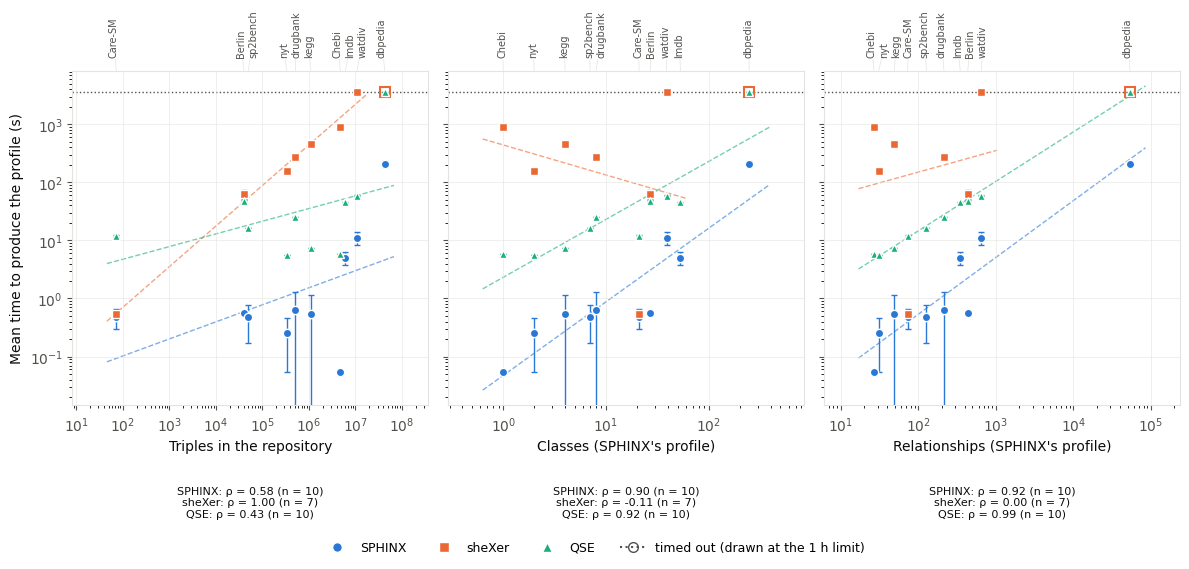

Spearman's rho of the mean extraction time against each measure


,extractor,measure,measured_by,n,rho,p,excluded
0,SPHINX,dataset_triples,endpoint,10,0.5758,None,
1,SPHINX,classes,SPHINX's profile,10,0.9030,None,
2,SPHINX,relationships,SPHINX's profile,10,0.9152,None,
3,sheXer,dataset_triples,endpoint,7,1.0000,None,dbpedia (timeout); lmdb (ValueError: Is this l...
4,sheXer,classes,SPHINX's profile,7,-0.1071,None,dbpedia (timeout); lmdb (ValueError: Is this l...
5,sheXer,relationships,SPHINX's profile,7,0.0000,None,dbpedia (timeout); lmdb (ValueError: Is this l...
6,QSE,dataset_triples,endpoint,10,0.4303,None,
7,QSE,classes,SPHINX's profile,10,0.9152,None,
8,QSE,relationships,SPHINX's profile,10,0.9879,None,
9,SPHINX,classes,the tool's own profile,10,0.9030,None,


In [16]:
# ------------------------------------------------------
# Figure: extraction time against dataset size and structure, per extractor
# ------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.transforms import blended_transform_factory

FIGURE_FILE = OUT_DIR / "extraction_time_scaling"     # written as .pdf and .png
STRUCTURE_FROM = "sphinx"   # "sphinx": one structural measure for all; "own": each tool's counts

# Categorical slots 1-3 of the reference palette (validated for scatter use);
# marker shape is a second encoding, so no tool is told apart by colour alone.
TOOL_STYLE = {
    "sphinx": ("SPHINX", "#2a78d6", "o"),
    "shexer": ("sheXer", "#eb6834", "s"),
    "qse":    ("QSE",    "#1baf7a", "^"),
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

PANELS = [
    ("dataset_triples", "Triples in the repository"),
    ("classes", "Classes"),
    ("relationships", "Relationships"),
]


def spearman(x, y):
    """Spearman's rho, with a p-value when scipy is available."""
    rho = x.rank().corr(y.rank())
    try:
        from scipy.stats import spearmanr
        return rho, spearmanr(x, y).pvalue
    except ImportError:
        return rho, None


def with_structure(frame, basis):
    """Add `classes` and `relationships` columns from SPHINX's or each tool's profile."""
    frame = frame.copy()
    if basis == "sphinx":
        sphinx = frame[frame["extractor"] == "sphinx"].set_index("dataset")
        frame["classes"] = frame["dataset"].map(sphinx["node_shapes"])
        frame["relationships"] = frame["dataset"].map(sphinx["property_shapes"])
    elif basis == "own":
        frame["classes"] = frame["node_shapes"]
        frame["relationships"] = frame["property_shapes"]
    else:
        raise ValueError(f"Unknown STRUCTURE_FROM: {basis}")
    return frame


scaling = extraction_summary[extraction_summary["extractor"].isin(TOOL_STYLE)].copy()
status = scaling["status"].astype(str)
scaling["finished"] = (status == "ok") & scaling["time_s_mean"].notna()
scaling["timed_out"] = status.str.startswith("timeout")

# --- Spearman's rho, for both structural bases -------------------------------
rho_rows = []
for basis in ("sphinx", "own"):
    frame = with_structure(scaling, basis)
    for extractor in TOOL_STYLE:
        rows = frame[frame["extractor"] == extractor]
        for column, _ in PANELS:
            if column == "dataset_triples" and basis == "own":
                continue                          # the same in both bases
            usable = rows[rows["finished"] & rows[column].notna() & (rows[column] > 0)]
            excluded = rows[~rows.index.isin(usable.index)]
            rho, p = (spearman(usable[column].astype(float), usable["time_s_mean"])
                      if len(usable) >= 3 else (float("nan"), None))
            rho_rows.append({
                "extractor": TOOL_STYLE[extractor][0], "measure": column,
                "measured_by": "endpoint" if column == "dataset_triples" else
                               ("SPHINX's profile" if basis == "sphinx" else "the tool's own profile"),
                "n": len(usable), "rho": rho, "p": p,
                "excluded": "; ".join(f"{d} ({s})" for d, s in zip(excluded["dataset"], excluded["status"])),
            })
spearman_table = pd.DataFrame(rho_rows).round(4)
spearman_table.to_csv(OUT_DIR / "extraction_time_spearman.csv", index=False)

# --- Figure -------------------------------------------------------------------
data = with_structure(scaling, STRUCTURE_FROM)
finished, timed_out = data[data["finished"]], data[data["timed_out"]]

fig, axes = plt.subplots(1, 3, figsize=(12, 5.2), sharey=True)
dataset_names = {}
for ax, (column, xlabel) in zip(axes, PANELS):
    stats = []
    for extractor, (name, color, marker) in TOOL_STYLE.items():
        done = finished[(finished["extractor"] == extractor) & (finished[column] > 0)]
        x, y = done[column].astype(float), done["time_s_mean"]
        if len(done) >= 3:
            slope, intercept = np.polyfit(np.log10(x), np.log10(y), 1)
            xs = np.logspace(np.log10(x.min()) - 0.2, np.log10(x.max()) + 0.2, 50)
            ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)),
                    ls="--", lw=1, color=color, alpha=0.6, zorder=1)
            rho, p = spearman(x, y)
            p_text = "" if p is None else (", p < 0.001" if p < 0.001 else f", p = {p:.3f}")
            stats.append(f"{name}: ρ = {rho:.2f} (n = {len(done)}{p_text})")
        else:
            stats.append(f"{name}: n = {len(done)}, too few for ρ")
        ax.errorbar(x, y, yerr=done["time_s_std"], fmt=marker, ms=6, color=color,
                    mec="white", mew=1, ecolor=color, elinewidth=1, capsize=2, zorder=3)
        late = timed_out[(timed_out["extractor"] == extractor) & (timed_out[column] > 0)]
        if len(late):
            ax.plot(late[column].astype(float), [EXTRACTOR_TIMEOUT] * len(late), marker,
                    ms=7, mfc="none", mec=color, mew=1.5, ls="none", zorder=3)

    if len(timed_out):
        ax.axhline(EXTRACTOR_TIMEOUT, ls=":", lw=1, color=MUTED, zorder=0)

    # Datasets named along the top: all tools share x, so one name per position.
    positions = (data.dropna(subset=[column]).query(f"{column} > 0")
                 .groupby(column)["dataset"].agg(lambda s: ", ".join(dict.fromkeys(s))))
    dataset_names[ax] = positions

    # Below the axes, so it never covers a data point.
    ax.text(0.5, -0.24, "\n".join(stats), transform=ax.transAxes, ha="center", va="top",
            fontsize=8, color=INK)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel + ("" if column == "dataset_triples" else
                            " (SPHINX's profile)" if STRUCTURE_FROM == "sphinx" else " (each tool's profile)"),
                  color=INK)
    ax.grid(True, which="major", lw=0.4, color=GRID)
    ax.tick_params(colors=MUTED)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    ax.margins(x=0.12)

axes[0].set_ylabel("Mean time to produce the profile (s)", color=INK)
handles = [Line2D([], [], marker=m, color=c, mec="white", ls="none", ms=7, label=n)
           for n, c, m in TOOL_STYLE.values()]
if len(timed_out):
    handles.append(Line2D([], [], marker="o", mfc="none", mec=MUTED, ls=":", color=MUTED, ms=7,
                          label=f"timed out (drawn at the {EXTRACTOR_TIMEOUT / 3600:g} h limit)"))
fig.tight_layout(rect=(0, 0.05, 1, 1))


def name_datasets(ax, positions, min_gap_pt=9):
    """Dataset names along the top of a panel, spread apart where positions are
    close, each joined to its true position by a short leader line."""
    to_pt = 72 / fig.dpi
    along_top = blended_transform_factory(ax.transData, ax.transAxes)
    xs = [ax.transData.transform((float(x), 1))[0] * to_pt for x in positions.index]
    placed = []
    for x in xs:                                  # sweep left to right
        placed.append(max(x, placed[-1] + min_gap_pt) if placed else x)
    shift = (sum(placed) - sum(xs)) / len(xs)     # re-centre the spread
    for (position, names), x, target in zip(positions.items(), xs, placed):
        ax.annotate(names, (float(position), 1.0), xycoords=along_top,
                    xytext=(target - shift - x, 10), textcoords="offset points",
                    rotation=90, ha="center", va="bottom", fontsize=7, color=MUTED,
                    annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", lw=0.5, color=GRID, shrinkA=0, shrinkB=0))


for ax, positions in dataset_names.items():
    name_datasets(ax, positions)
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           fontsize=9, bbox_to_anchor=(0.5, 0.02))
fig.savefig(f"{FIGURE_FILE}.pdf", bbox_inches="tight")
fig.savefig(f"{FIGURE_FILE}.png", dpi=300, bbox_inches="tight")
plt.show()

print("Spearman's rho of the mean extraction time against each measure")
display(spearman_table)

## 4. RIDDLE compared with FedX, CostFed and DeTrusty

This part compares source selection over the LargeRDFBench simple queries
(S1–S14), the only workload whose queries span several repositories. FedX,
CostFed and DeTrusty are run over the SPARQL endpoints of the six
LargeRDFBench datasets. RIDDLE's figures are those of `Benchmarks.ipynb`
(part 3), obtained from the SPHINX profiles of the same repositories.

**How each system is run.**

* **FedX and CostFed** are run from the CostFed repository, which contains
  CostFed and the FedX code base it extends, each with the configuration file
  shipped for it (`costfed.props`, `fedx.props`). The only keys changed are the
  query timeout, the location of the ASK cache (a fresh file per run, so that
  every run starts with an empty cache) and the location of CostFed's index.
  `endpointProviderClass` is removed from `costfed.props`, since it would
  replace the endpoints given on the command line with a directory watcher.
  Both engines are driven by `NileComparisonDriver` (see `SETUP.md`), one query
  per JVM, which reads the source selection FedX records for every query
  (`QueryInfo.getSourceSelection()`: its duration and the sources chosen for
  each triple pattern) and, for CostFed, the number of remote ASK checks it
  issued.
* **DeTrusty** is run as a library, in a forked process per query. Its source
  selection is its query decomposition, which only reads the RDF-MTs, so it is
  timed separately by calling the decomposer on its own, and the sources chosen
  for each triple pattern are read from the `Service` nodes it produces. The
  query is then executed with `run_query`, with the default star-shaped
  decomposition and joins performed by DeTrusty.

Every query is run by every engine `REPEATS` times. The same runs provide the
execution figures of part 6, so each engine is run once for both
comparisons.

**Measures** (as in the thesis):

* **TPWSS**, reported two ways. `tpwss` counts only triple patterns that are
  not `rdf:type` patterns, which is the definition used for RIDDLE in
  `Benchmarks.ipynb` (and includes variable-predicate patterns, as
  `INCLUDE_VARIABLE_PREDICATES` does there). `tpwss_all` counts every pattern,
  which is the convention of LargeRDFBench and of the figures published for
  FedX and CostFed.
* **Requests issued for selection**: CostFed's remote ASK checks as it records
  them; for FedX, one ASK per triple pattern and endpoint, which is what its
  source selection sends with an empty cache; none for DeTrusty and RIDDLE.
  The column `ask_requests_basis` says which applies.
* **Source selection time**: as FedX measures it for FedX and CostFed (cold
  ASK cache, so including the ASK round trips), the decomposition time for
  DeTrusty, and the warm- and cold-cache times of `Benchmarks.ipynb` for
  RIDDLE.
* **Index construction time**, for CostFed's index and DeTrusty's RDF-MTs,
  built here, and for the SPHINX profiles, from `profile_runs.csv`.
* **Precision and recall** of the endpoint-level selection against ground
  truth (a) of `Benchmarks.ipynb`, the pattern ground truth: an endpoint is
  relevant to a query when at least one of its non-`rdf:type` triple patterns
  matches there. An engine's selection is the set of endpoints it chose for any
  pattern of the query, that is, the endpoints it will contact.

### 4.1 Configuration

`ENGINE_ENDPOINTS` is the federation given to FedX, CostFed and DeTrusty: the
SPARQL endpoints of the six LargeRDFBench datasets, identified by URL. Both
CostFed's index and DeTrusty's RDF-MTs record the endpoints by URL, so they
must be built from exactly these URLs.

`COSTFED_BRANCH_LIMIT` is the depth of the prefix trees in CostFed's index;
4 is the value used by CostFed's own index generator. Existing indexes are
reused unless `REBUILD_INDEXES` is set; their construction time is then read
from `index_construction.csv`.

In [5]:
# ------------------------------------------------------
# RIDDLE comparison: configuration
# ------------------------------------------------------
ENGINES = ["FedX", "CostFed", "DeTrusty"]
ENGINE_ENDPOINTS = [endpoints[label] for label in LRB_LABELS]

FEDX_PROPS_TEMPLATE = COSTFED_DIR / "costfed" / "fedx.props"
COSTFED_PROPS_TEMPLATE = COSTFED_DIR / "costfed" / "costfed.props"
COSTFED_BRANCH_LIMIT = 4
COSTFED_INDEX = (OUT_DIR / "costfed" / "summaries.n3").resolve()

DETRUSTY_CONFIG = (OUT_DIR / "detrusty" / "rdfmts.ttl").resolve()
DETRUSTY_DECOMPOSITION = "STAR"
DETRUSTY_JOIN_STARS_LOCALLY = True

REBUILD_INDEXES = False

JAVA_CLASSPATH = f"{COSTFED_JAR.resolve()}{os.pathsep}{DRIVER_DIR.resolve()}"

lrb_queries = {key: path for key, path in queries.items() if key[0] == LRB}
print(f"{len(lrb_queries)} LargeRDFBench queries; federation of {len(ENGINE_ENDPOINTS)} endpoints.")

14 LargeRDFBench queries; federation of 6 endpoints.


### 4.2 Index construction

CostFed's index is built with its own summary generator
(`TBSSSummariesGenerator`, through the driver's `index` mode), DeTrusty's
RDF-MTs with its own `create_rdfmts`. Both are timed from start to the index
being written. SPHINX's figures are taken from `profile_runs.csv`, summed over
the six datasets, in two variants: the first repetition, which ran against
endpoints whose caches had not seen SPHINX's queries, and the mean of the
measured repetitions. The first is the one comparable with the single build
of the other two indexes. The size of each index on disk is reported as well.

Unlike the other two, the SPHINX profiles are not built for this federation:
each describes one repository, is built once by its owner, and is reused by
any federation that includes the repository (part 6 uses all ten).

In [13]:
# ------------------------------------------------------
# Index construction
# ------------------------------------------------------
INDEX_CSV = OUT_DIR / "index_construction.csv"
previous = pd.read_csv(INDEX_CSV) if INDEX_CSV.exists() else pd.DataFrame(columns=["system"])


def previous_row(system):
    rows = previous[previous["system"] == system]
    return rows.iloc[-1].to_dict() if len(rows) else None


def _build_detrusty_index(urls, target):
    from DeTrusty.Molecule.MTCreation import create_rdfmts
    t0 = time.perf_counter()
    create_rdfmts(list(urls), str(target))
    return {"status": "ok", "time_s": time.perf_counter() - t0}


index_rows = []

# CostFed
if COSTFED_INDEX.exists() and not REBUILD_INDEXES and previous_row("CostFed"):
    index_rows.append(previous_row("CostFed"))
    print("CostFed index reused.")
else:
    COSTFED_INDEX.parent.mkdir(parents=True, exist_ok=True)
    COSTFED_INDEX.unlink(missing_ok=True)
    print("Building CostFed index ...", flush=True)
    status, elapsed = run_process(
        [JAVA8, f"-Xmx{ENGINE_XMX}", "-cp", JAVA_CLASSPATH, "NileComparisonDriver", "index",
         COSTFED_INDEX, COSTFED_BRANCH_LIMIT, *ENGINE_ENDPOINTS],
        INDEX_TIMEOUT, WORK_DIR / "logs" / "costfed_index.log", cwd=COSTFED_DIR / "costfed")
    index_rows.append({"system": "CostFed", "status": status, "time_s": elapsed})

# DeTrusty
if DETRUSTY_CONFIG.exists() and not REBUILD_INDEXES and previous_row("DeTrusty"):
    index_rows.append(previous_row("DeTrusty"))
    print("DeTrusty RDF-MTs reused.")
else:
    DETRUSTY_CONFIG.parent.mkdir(parents=True, exist_ok=True)
    DETRUSTY_CONFIG.unlink(missing_ok=True)
    print("Building DeTrusty RDF-MTs ...", flush=True)
    result = run_in_child(_build_detrusty_index, (ENGINE_ENDPOINTS, DETRUSTY_CONFIG),
                          INDEX_TIMEOUT, WORK_DIR / "logs" / "detrusty_index.log")
    index_rows.append({"system": "DeTrusty", "status": result.get("status"),
                       "time_s": result.get("time_s")})

for row in index_rows:
    target = COSTFED_INDEX if row["system"] == "CostFed" else DETRUSTY_CONFIG
    row["bytes"] = target.stat().st_size if target.exists() else None

# SPHINX, from Benchmarks.ipynb
profile_runs = pd.read_csv(BENCHMARK_DIR / "profile_runs.csv")
lrb_profile_runs = profile_runs[profile_runs["dataset"].isin(LRB_LABELS) & (profile_runs["status"] == "ok")]
first_runs = lrb_profile_runs[lrb_profile_runs["repetition"] == 1]
index_rows.append({"system": "SPHINX (first repetition)", "status": "ok",
                   "time_s": first_runs["total_s"].sum(),
                   "bytes": first_runs["shapes_bytes"].sum()})
index_rows.append({"system": "SPHINX (mean of measured repetitions)", "status": "ok",
                   "time_s": measured_runs(lrb_profile_runs.assign(status="ok"))
                             .groupby("dataset")["total_s"].mean().sum(),
                   "bytes": first_runs["shapes_bytes"].sum()})
if first_runs["dataset"].nunique() != len(LRB_LABELS):
    print("Warning: profile_runs.csv lacks a successful run for some LargeRDFBench datasets.")

index_construction = pd.DataFrame(index_rows)[["system", "status", "time_s", "bytes"]].round(3)
index_construction.to_csv(INDEX_CSV, index=False)
display(index_construction)

# CostFed does not fail when its index is missing: it logs "can't load summary"
# and every query then fails with a NullPointerException in lookupFedSum.
if not COSTFED_INDEX.exists() or COSTFED_INDEX.stat().st_size == 0:
    print(f"Warning: CostFed's index {COSTFED_INDEX} was not built; CostFed cannot run. "
          f"See {WORK_DIR / 'logs' / 'costfed_index.log'} and re-run this cell.")

Building CostFed index ...
Building DeTrusty RDF-MTs ...


,system,status,time_s,bytes
0,CostFed,ok,18.888,1502
1,DeTrusty,ok,659.649,8320288
2,SPHINX (first repetition),ok,192.901,6790269
3,SPHINX (mean of measured repetitions),ok,187.717,6790269


### 4.3 Running one query per engine

`run_fedx_family` runs one query with FedX or CostFed. A configuration file is
written for the run from the shipped template, with the changes described
above, and the driver is started in a fresh JVM in CostFed's module
directory, which is where the shipped configuration expects to be run from.
The driver writes the answer and a metrics file; both are read back here. A
run that reaches the engine's own time limit (`enforceMaxQueryTime`) ends with
a `QueryInterruptedException`, which is recorded as a timeout, as is a JVM
that has to be killed. If the JVM fails before the driver writes its metrics,
the first error line of the run's log is added to the status.

`run_detrusty` runs one query with DeTrusty in a forked process: it loads the
RDF-MTs, times the decomposition on its own, collects the `Service` nodes of
the decomposed query, and then executes the query with `run_query`. DeTrusty
prints the query while decomposing it; that output goes to the run's log.
DeTrusty treats a failed request to an endpoint as an empty answer from it and
only logs the error, so the errors of its SPARQL wrapper are captured, and a
run in which any request failed is recorded as failed rather than as a
successful run with fewer results. A query whose variables are bound only by
variable-predicate patterns (LargeRDFBench S1 and S9) cannot be decomposed:
DeTrusty selects sources from constant predicates, drops the patterns it finds
none for, and then rejects the query because the variables those patterns bound
are gone. Such runs are recorded as `unsupported`, not as failures. When
the decomposition finds no source for the query, DeTrusty reports that the
query cannot be answered: this is recorded as a successful run with no source
selected and an empty answer, as RIDDLE's empty selections are in
`Benchmarks.ipynb`.

Both return the same record: status, timings (milliseconds), number of
results, ASK requests where recorded, and the selection as a list of
(pattern, endpoints, is `rdf:type` pattern).

In [6]:
# ------------------------------------------------------
# Engine runners
# ------------------------------------------------------
TYPE_TERM = f"<{RDF_TYPE}>"
TYPE_NAMES = {TYPE_TERM, "a", "rdf:type", RDF_TYPE}


def write_props(template, target, overrides, drop=()):
    """A copy of a Java properties file with some keys changed or removed."""
    lines, done = [], set()
    for line in Path(template).read_text().splitlines():
        stripped = line.strip()
        key = stripped.split("=", 1)[0].strip() if "=" in stripped and not stripped.startswith("#") else None
        if key in drop:
            lines.append(f"# {line}    (removed for the comparison)")
        elif key in overrides:
            lines.append(f"{key}={overrides[key]}")
            done.add(key)
        else:
            lines.append(line)
    lines += [f"{k}={v}" for k, v in overrides.items() if k not in done]
    Path(target).write_text("\n".join(lines) + "\n")


def run_dir_for(engine, query, repetition):
    directory = WORK_DIR / "engines" / engine / f"{query}_{repetition}"
    shutil.rmtree(directory, ignore_errors=True)
    directory.mkdir(parents=True)
    return directory


def first_error_line(log_path):
    """The first line of a log that names an error or exception, if any."""
    path = Path(log_path)
    if not path.exists():
        return None
    for line in path.read_text(errors="replace").splitlines():
        if re.search(r"(Error|Exception|Could not find or load main class)", line) \
                and "JNI error has occurred" not in line:
            return line.strip()[:300]
    return None


def run_fedx_family(engine, query_path, run_dir):
    template = COSTFED_PROPS_TEMPLATE if engine == "CostFed" else FEDX_PROPS_TEMPLATE
    props = run_dir / "engine.props"
    write_props(template, props, {
        "cacheLocation": (run_dir / "cache.db").resolve(),  # fresh: empty ASK cache
        "enforceMaxQueryTime": ENGINE_TIMEOUT,
        "quetzal.fedSummaries": COSTFED_INDEX,
    }, drop=("endpointProviderClass",))
    results, metrics_file = run_dir / "results.json", run_dir / "metrics.json"
    status, wall_s = run_process(
        [JAVA8, f"-Xmx{ENGINE_XMX}", "-cp", JAVA_CLASSPATH, "NileComparisonDriver", "query",
         props.resolve(), query_path, results.resolve(), metrics_file.resolve(), *ENGINE_ENDPOINTS],
        ENGINE_TIMEOUT + 120, run_dir / "engine.log", cwd=COSTFED_DIR / "costfed")
    metrics = json.loads(metrics_file.read_text()) if metrics_file.exists() else {}
    if status == "ok":
        status = metrics.get("status", "no metrics written")
    elif not metrics:
        # The JVM failed before the driver could write its metrics (for instance
        # the driver class not found, or compiled for a newer Java than 8).
        cause = first_error_line(run_dir / "engine.log")
        if cause:
            status = f"{status}: {cause}"
    if "QueryInterrupted" in str(status):
        status = "timeout"
    selection = [(f"{p['s']} {p['p']} {p['o']}", sorted({label_of(u) for u in p["sources"]}),
                  p["p"] in TYPE_NAMES)
                 for p in metrics.get("patterns", [])]
    return {
        "status": status,
        "selection_ms": metrics.get("source_selection_ms"),
        "first_result_ms": metrics.get("first_result_ms"),
        "total_ms": metrics.get("total_ms"),
        "wall_s": wall_s,
        "results": metrics.get("results"),
        "ask_requests": metrics.get("ask_requests"),
        "selection": selection,
        "results_file": str(results),
    }


def _detrusty_query(config_path, query_text, results_path):
    """Body of the DeTrusty child process."""
    from DeTrusty import get_config, run_query
    from DeTrusty.Decomposer import Decomposer
    from DeTrusty.Sparql.utils import Service, Triple

    config = get_config(str(config_path))

    t0 = time.perf_counter()
    decomposed = Decomposer(query_text, config, decompType=DETRUSTY_DECOMPOSITION,
                            joinstarslocally=DETRUSTY_JOIN_STARS_LOCALLY).decompose()
    selection_ms = (time.perf_counter() - t0) * 1000

    # Every Service node, and the triple patterns under it.
    services, seen = [], set()

    def walk(node):
        if node is None or id(node) in seen or isinstance(node, (str, int, float, bool)):
            return
        seen.add(id(node))
        if isinstance(node, Service):
            services.append(node)
        if isinstance(node, dict):
            for value in node.values():
                walk(value)
        elif isinstance(node, (list, tuple, set)):
            for value in node:
                walk(value)
        elif hasattr(node, "__dict__"):
            for value in vars(node).values():
                walk(value)

    walk(decomposed)
    chosen = {}
    for service in services:
        triples, stack, visited = [], [service.triples], set()
        while stack:
            item = stack.pop()
            if id(item) in visited:
                continue
            visited.add(id(item))
            if isinstance(item, Triple):
                triples.append(item)
            elif isinstance(item, (list, tuple, set)):
                stack.extend(item)
            elif hasattr(item, "__dict__"):
                stack.extend(vars(item).values())
        for triple in triples:
            key = repr(triple).strip()
            entry = chosen.setdefault(key, {"sources": set(),
                                            "is_type": triple.predicate.name in TYPE_NAMES})
            entry["sources"].add(service.endpoint)

    if decomposed is None:
        Path(results_path).write_text(json.dumps({"head": {}, "results": {"bindings": []}}))
        return {"status": "ok", "note": "no source selected", "selection_ms": selection_ms,
                "total_ms": selection_ms, "results": 0, "selection": []}

    # DeTrusty logs a failed request to an endpoint and carries on as if the
    # endpoint had returned nothing, so the run would look successful. Its
    # wrapper's errors are captured in a file (the handler is inherited by the
    # processes DeTrusty forks) and turn the run into a failure.
    errors_path = Path(results_path).with_name("detrusty_errors.log")
    handler = logging.FileHandler(errors_path)
    handler.setLevel(logging.ERROR)
    logging.getLogger("DeTrusty.Wrapper.RDFWrapper").addHandler(handler)

    t1 = time.perf_counter()
    answer = run_query(query_text, decomposition_type=DETRUSTY_DECOMPOSITION, config=config,
                       join_stars_locally=DETRUSTY_JOIN_STARS_LOCALLY, print_result=True)
    total_ms = (time.perf_counter() - t1) * 1000
    handler.flush()
    bindings = answer.get("results", {}).get("bindings", [])
    Path(results_path).write_text(json.dumps({"head": answer.get("head", {}),
                                              "results": {"bindings": bindings}}))
    status = answer.get("error", "ok")
    request_errors = [l for l in errors_path.read_text(errors="replace").splitlines()
                      if l.strip()] if errors_path.exists() else []
    if status == "ok" and request_errors:
        status = f"endpoint request failed ({len(request_errors)}): {request_errors[0][:200]}"
    return {
        "status": status,
        "selection_ms": selection_ms,
        "total_ms": total_ms,
        "results": answer.get("cardinality", len(bindings)),
        "selection": [(k, sorted(v["sources"]), v["is_type"]) for k, v in chosen.items()],
    }


# DeTrusty selects sources from the constant predicates of a query's triple
# patterns. A pattern with a variable predicate that no other pattern connects
# (e.g. `<x> ?p ?o`) gets no source and is dropped, and DeTrusty then rejects the
# query because the variables it bound are gone. That is a limitation of its
# source selection, recorded as "unsupported" rather than as a failed run.
DETRUSTY_UNSUPPORTED = (
    "have been defined in the SELECT clause but not in the body",
    "have been defined in the GROUP BY clause but not in the body",
)


def run_detrusty(query_path, run_dir):
    results = run_dir / "results.json"
    result = run_in_child(_detrusty_query,
                          (DETRUSTY_CONFIG, query_path.read_text(encoding="utf-8"), results),
                          ENGINE_TIMEOUT, run_dir / "engine.log")
    if any(marker in str(result.get("status")) for marker in DETRUSTY_UNSUPPORTED):
        result["note"] = result["status"]
        result["status"] = "unsupported: variable-predicate patterns without a source"
    result["selection"] = [(key, sorted({label_of(u) for u in sources}), is_type)
                           for key, sources, is_type in result.get("selection", [])]
    result.update(ask_requests=0, first_result_ms=None, results_file=str(results))
    return result

### 4.4 Measured runs

Every LargeRDFBench query is run by every engine `REPEATS` times. The
per-run records go to `engine_runs.csv`. The selection and the answer of the
last successful repetition of each query are kept (`engine_selection`,
`engine_answers`) for 4.5 and for part 6; an answer cut short by a timeout is
kept with `complete = False`, so that part 6 can report the completeness
reached before the time limit.

Before the loop, the first query is run once by each engine as a smoke test,
so that a configuration problem is found before hours are spent.

In [20]:
# ------------------------------------------------------
# Engines: smoke test
# ------------------------------------------------------
smoke_key = next(iter(lrb_queries))
for engine in ENGINES:
    run_dir = run_dir_for(engine, f"smoke_{smoke_key[1]}", 0)
    runner = run_detrusty if engine == "DeTrusty" else (lambda p, d, e=engine: run_fedx_family(e, p, d))
    outcome = runner(lrb_queries[smoke_key], run_dir)
    print(f"{engine}: {outcome['status']}, {outcome.get('results')} results, "
          f"{len(outcome.get('selection', []))} patterns; log: {run_dir / 'engine.log'}")
    # For FedX and CostFed, show where an exception was raised: the driver writes
    # the stack trace to the run's metrics file.
    metrics_file = run_dir / "metrics.json"
    if outcome["status"] != "ok" and metrics_file.exists():
        trace = json.loads(metrics_file.read_text()).get("trace", "")
        lines = [l for l in trace.splitlines() if l.strip()]
        caused = [i for i, l in enumerate(lines) if l.lstrip().startswith("Caused by")]
        start = caused[-1] if caused else 0          # the innermost cause
        print("    " + "\n    ".join(lines[start:start + 12]))

FedX: ok, 90 results, 3 patterns; log: comparison_work/engines/FedX/smoke_S1_0/engine.log
CostFed: ok, 77 results, 3 patterns; log: comparison_work/engines/CostFed/smoke_S1_0/engine.log
DeTrusty: unsupported: variable-predicate patterns without a source, None results, 0 patterns; log: comparison_work/engines/DeTrusty/smoke_S1_0/engine.log


In [21]:
# ------------------------------------------------------
# Engines: measured runs
# ------------------------------------------------------
engine_records, engine_selection, engine_answers = [], {}, {}

for engine in ENGINES:
    for n, ((benchmark, query), path) in enumerate(lrb_queries.items(), 1):
        print(f"{engine} [{n}/{len(lrb_queries)}] {query}")
        for repetition in range(1, REPEATS + 1):
            run_dir = run_dir_for(engine, query, repetition)
            if engine == "DeTrusty":
                outcome = run_detrusty(path, run_dir)
            else:
                outcome = run_fedx_family(engine, path, run_dir)

            answer, complete = read_results_file(outcome["results_file"])
            if outcome.get("note") == "no source selected":
                answer, complete = empty_answer(features[(benchmark, query)]["form"]), True
            record = {
                "engine": engine, "benchmark": benchmark, "query": query,
                "repetition": repetition, "status": outcome.get("status"),
                "note": outcome.get("note"),
                "selection_ms": outcome.get("selection_ms"),
                "first_result_ms": outcome.get("first_result_ms"),
                "total_ms": outcome.get("total_ms"),
                "results": outcome.get("results"),
                "answer_complete": complete,
                "ask_requests": outcome.get("ask_requests"),
                "patterns_selected": len(outcome.get("selection") or []),
            }
            engine_records.append(record)
            # A run cut short keeps the selection only if it was recorded (FedX
            # and CostFed record it before execution starts; DeTrusty does not).
            if record["status"] == "ok" or outcome.get("selection"):
                engine_selection[(engine, query)] = outcome.get("selection") or []
            if answer is not None and (record["status"] == "ok" or (engine, query) not in engine_answers):
                engine_answers[(engine, query)] = (answer, complete)
            print(f"    {repetition}/{REPEATS}: {record['status']}, "
                  f"selection {record['selection_ms']} ms, total {record['total_ms']} ms, "
                  f"{record['results']} results")

engine_runs = pd.DataFrame(engine_records)
engine_runs.to_csv(OUT_DIR / "engine_runs.csv", index=False)

FedX [1/14] S1
    1/2: ok, selection 199 ms, total 295.562029 ms, 90 results
    2/2: ok, selection 245 ms, total 396.724007 ms, 90 results
FedX [2/14] S10
    1/2: ok, selection 391 ms, total 33138.463737 ms, 9054 results
    2/2: ok, selection 349 ms, total 35060.480943 ms, 9054 results
FedX [3/14] S11
    1/2: ok, selection 318 ms, total 412.539489 ms, 3 results
    2/2: ok, selection 256 ms, total 346.119694 ms, 3 results
FedX [4/14] S12
    1/2: ok, selection 315 ms, total 6266.676088 ms, 393 results
    2/2: ok, selection 367 ms, total 8764.213706 ms, 393 results
FedX [5/14] S13
    1/2: ok, selection 465 ms, total 383418.678255 ms, 28 results
    2/2: ok, selection 279 ms, total 384500.567673 ms, 28 results
FedX [6/14] S14
    1/2: ok, selection 298 ms, total 78258.951188 ms, 1620 results
    2/2: ok, selection 271 ms, total 78197.547369 ms, 1620 results
FedX [7/14] S2
    1/2: ok, selection 270 ms, total 324.461823 ms, 1 results
    2/2: ok, selection 170 ms, total 199.586262 

### 4.5 Source selection per query

For every engine and query, the selection of the last successful repetition
is scored against ground truth (a), taken from `riddle_patterns.csv`. The
timings are averaged over the measured repetitions. RIDDLE's rows are taken
from `riddle_queries.csv`, with the same columns: its `tpwss` is
`tpwss_riddle` (the pairs it would select pattern by pattern), and two further
columns give `tpwss_effective` (the pairs SCARAB requests, patterns times
selected endpoints) and `tpwss_optimal` (a perfect pattern-level selector).
RIDDLE's `tpwss_all` is left empty, since RIDDLE does not select sources for
`rdf:type` patterns: SCARAB requests them from every selected endpoint, which
`tpwss_effective` already covers for the other patterns.

Queries whose ground truth is incomplete (a failed probe in
`Benchmarks.ipynb`) are flagged and excluded from the aggregates, as there.

In [22]:
# ------------------------------------------------------
# Source selection per query
# ------------------------------------------------------
riddle_patterns = pd.read_csv(BENCHMARK_DIR / "riddle_patterns.csv")
riddle_patterns = riddle_patterns[riddle_patterns["benchmark"] == LRB].copy()
for column in ("counts", "selected", "gt_a", "gt_b"):
    riddle_patterns[column] = as_bool(riddle_patterns[column])
counted = riddle_patterns[riddle_patterns["counts"] == True]

relevant_a = {q: set(g.loc[g["gt_a"] == True, "dataset"]) for q, g in counted.groupby("query")}
unknown_gt = {q: bool(g[["gt_a", "gt_b"]].isna().any().any()) for q, g in counted.groupby("query")}

riddle_queries = pd.read_csv(BENCHMARK_DIR / "riddle_queries.csv")
riddle_queries = riddle_queries[riddle_queries["benchmark"] == LRB].set_index("query")
typing = riddle_queries["typing"].to_dict()


def split_labels(value):
    return {v.strip() for v in str(value).split(",") if v.strip()} if pd.notna(value) else set()


def score(selected, relevant):
    tp, fp, fn = len(selected & relevant), len(selected - relevant), len(relevant - selected)
    return {"tp": tp, "fp": fp, "fn": fn,
            "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn)}


timing = summarise_repetitions(engine_runs, ["engine", "query"], ["selection_ms"])

selection_rows = []
for engine in ENGINES:
    for (_, query) in lrb_queries:
        chosen = engine_selection.get((engine, query))
        row = {"system": engine, "query": query, "typing": typing.get(query),
               "unknown_ground_truth": unknown_gt.get(query, False)}
        if chosen is None:
            row["status"] = "no selection recorded"
            selection_rows.append(row)
            continue
        selected = set().union(*(set(sources) for _, sources, _ in chosen)) if chosen else set()
        relevant = relevant_a.get(query, set())
        row.update(score(selected, relevant))
        row.update({
            "selected": ", ".join(sorted(selected)),
            "relevant": ", ".join(sorted(relevant)),
            "tpwss": sum(len(sources) for _, sources, is_type in chosen if not is_type),
            "tpwss_all": sum(len(sources) for _, sources, _ in chosen),
        })
        if engine == "FedX":
            row["ask_requests"] = len(chosen) * len(ENGINE_ENDPOINTS)
            row["ask_requests_basis"] = "analytical: patterns x endpoints"
        elif engine == "CostFed":
            asks = measured_runs(engine_runs[(engine_runs["engine"] == engine) &
                                             (engine_runs["query"] == query)])["ask_requests"]
            row["ask_requests"] = asks.mean() if len(asks) else None
            row["ask_requests_basis"] = "recorded by CostFed"
        else:
            row["ask_requests"] = 0
            row["ask_requests_basis"] = "none by design"
        t = timing[(timing["engine"] == engine) & (timing["query"] == query)]
        if len(t):
            row.update(status=t["status"].iloc[0], repetitions=t["repetitions"].iloc[0],
                       selection_ms_mean=t["selection_ms_mean"].iloc[0],
                       selection_ms_std=t["selection_ms_std"].iloc[0])
        selection_rows.append(row)

for query, r in riddle_queries.iterrows():
    selected = split_labels(r["selected"])
    relevant = relevant_a.get(query, set())
    selection_rows.append({
        "system": "RIDDLE", "query": query, "typing": r["typing"],
        "unknown_ground_truth": unknown_gt.get(query, False), "status": "ok",
        **score(selected, relevant),
        "selected": ", ".join(sorted(selected)), "relevant": ", ".join(sorted(relevant)),
        "tpwss": r["tpwss_riddle"], "tpwss_all": None,
        "tpwss_effective": r["tpwss_effective"], "tpwss_optimal": r["tpwss_optimal"],
        "ask_requests": 0, "ask_requests_basis": "none by design",
        "selection_ms_mean": r.get("warm_ms_mean"), "selection_ms_std": r.get("warm_ms_std"),
        "selection_ms_cold_mean": r.get("cold_ms_mean"),
    })

selection_df = pd.DataFrame(selection_rows).round(4)
selection_df.to_csv(OUT_DIR / "selection_per_query.csv", index=False)

# Consistency check: RIDDLE's scores recomputed here must equal Benchmarks.ipynb's.
import numpy as np

check = selection_df[selection_df["system"] == "RIDDLE"].set_index("query")
mine = check["recall"].astype(float)
theirs = riddle_queries.loc[check.index, "recall_a"].astype(float)
disagree = list(check.index[~np.isclose(mine, theirs, equal_nan=True)])
if disagree:
    print(f"Warning: RIDDLE recall differs from riddle_queries.csv for {disagree}")

### 4.6 Aggregates

`summarise_selection` produces, for any grouping, the micro-averaged precision
and recall (TP, FP and FN summed over queries), the macro-averaged ones (mean
of the per-query values where defined), the TPWSS sums, the ASK requests, and
the mean selection time. It is applied per system, and per system and typing
class: the typing class explains the rest, since RIDDLE can only act as a
predicate-level matcher on untyped queries.

| Column | Meaning |
| --- | --- |
| `micro_precision`, `micro_recall` | Endpoint-level selection against ground truth (a), micro-averaged. |
| `macro_precision`, `macro_recall` | The same, averaged over queries where defined. |
| `tpwss`, `tpwss_all` | Triple-pattern-wise sources selected, without and with `rdf:type` patterns. |
| `tpwss_effective` | RIDDLE only: pairs SCARAB requests. |
| `ask_requests` | Requests at selection time, on the basis stated per system in `selection_per_query.csv`. |
| `selection_ms_mean` | Mean source selection time per query (RIDDLE: warm profile cache). |

In [23]:
# ------------------------------------------------------
# Aggregates
# ------------------------------------------------------
def summarise_selection(frame, by):
    frame = frame[~frame["unknown_ground_truth"].astype(bool) & frame["tp"].notna()]
    out = []
    for key, g in frame.groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        tp, fp, fn = g["tp"].sum(), g["fp"].sum(), g["fn"].sum()
        out.append({
            **dict(zip(by, key)),
            "queries": len(g),
            "micro_precision": ratio(tp, tp + fp),
            "micro_recall": ratio(tp, tp + fn),
            "macro_precision": g["precision"].mean(),
            "macro_recall": g["recall"].mean(),
            "tpwss": g["tpwss"].sum(),
            "tpwss_all": g["tpwss_all"].sum(min_count=1),
            "tpwss_effective": g["tpwss_effective"].sum(min_count=1) if "tpwss_effective" in g else None,
            "ask_requests": g["ask_requests"].sum(min_count=1),
            "selection_ms_mean": g["selection_ms_mean"].mean(),
        })
    return pd.DataFrame(out).round(4)


selection_by_system = summarise_selection(selection_df, ["system"])
selection_by_typing = summarise_selection(selection_df, ["system", "typing"])
selection_by_system.to_csv(OUT_DIR / "selection_by_system.csv", index=False)
selection_by_typing.to_csv(OUT_DIR / "selection_by_typing.csv", index=False)

print("Index construction");          display(index_construction)
print("Source selection by system");  display(selection_by_system)
print("By system and typing class");  display(selection_by_typing)
print("Per query")
display(selection_df.sort_values(["query", "system"])[
    ["query", "typing", "system", "selected", "relevant", "precision", "recall",
     "tpwss", "tpwss_all", "ask_requests", "selection_ms_mean", "status"]])

Index construction


,system,status,time_s,bytes
0,CostFed,ok,18.888,1502
1,DeTrusty,ok,659.649,8320288
2,SPHINX (first repetition),ok,192.901,6790269
3,SPHINX (mean of measured repetitions),ok,187.717,6790269


Source selection by system


,system,queries,micro_precision,micro_recall,macro_precision,macro_recall,tpwss,tpwss_all,tpwss_effective,ask_requests,selection_ms_mean
0,CostFed,14,1.0000,0.0370,1.0000,0.0238,2.0,2.0,NaN,12.0,19.5714
1,DeTrusty,10,1.0000,0.2353,1.0000,0.3267,17.0,17.0,NaN,0.0,161.0874
2,FedX,14,1.0000,1.0000,1.0000,1.0000,93.0,98.0,NaN,366.0,281.9286
3,RIDDLE,14,0.9444,0.9444,0.9571,0.9524,90.0,NaN,214.0,0.0,54.3618


By system and typing class


,system,typing,queries,micro_precision,micro_recall,macro_precision,macro_recall,tpwss,tpwss_all,tpwss_effective,ask_requests,selection_ms_mean
0,CostFed,partially typed,4,NaN,0.0000,NaN,0.0000,0.0,0.0,NaN,0.0,7.3750
1,CostFed,untyped,10,1.0000,0.0488,1.00,0.0333,2.0,2.0,NaN,12.0,24.4500
2,DeTrusty,partially typed,4,NaN,0.0000,NaN,0.0000,0.0,0.0,NaN,0.0,1.1020
3,DeTrusty,untyped,6,1.0000,0.3810,1.00,0.5444,17.0,17.0,NaN,0.0,267.7444
4,FedX,partially typed,4,1.0000,1.0000,1.00,1.0000,27.0,31.0,NaN,138.0,315.8750
5,FedX,untyped,10,1.0000,1.0000,1.00,1.0000,66.0,67.0,NaN,228.0,268.3500
6,RIDDLE,partially typed,4,1.0000,0.9231,1.00,0.9167,25.0,NaN,55.0,0.0,47.7330
7,RIDDLE,untyped,10,0.9286,0.9512,0.94,0.9667,65.0,NaN,159.0,0.0,57.0133


Per query


,query,typing,system,selected,relevant,precision,recall,tpwss,tpwss_all,ask_requests,selection_ms_mean,status
14,S1,untyped,CostFed,dbpedia,"Chebi, dbpedia, drugbank, kegg, lmdb, nyt",1.0,0.1667,1.0,1.0,6.0,85.0000,ok
28,S1,untyped,DeTrusty,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no selection recorded
0,S1,untyped,FedX,"Chebi, dbpedia, drugbank, kegg, lmdb, nyt","Chebi, dbpedia, drugbank, kegg, lmdb, nyt",1.0,1.0000,8.0,8.0,18.0,222.0000,ok
42,S1,untyped,RIDDLE,"dbpedia, drugbank, kegg, lmdb, nyt","Chebi, dbpedia, drugbank, kegg, lmdb, nyt",1.0,0.8333,5.0,NaN,0.0,88.0440,ok
15,S10,untyped,CostFed,,"dbpedia, drugbank, kegg, lmdb, nyt",NaN,0.0000,0.0,0.0,0.0,9.0000,ok
29,S10,untyped,DeTrusty,,"dbpedia, drugbank, kegg, lmdb, nyt",NaN,0.0000,0.0,0.0,0.0,0.7061,ok
1,S10,untyped,FedX,"dbpedia, drugbank, kegg, lmdb, nyt","dbpedia, drugbank, kegg, lmdb, nyt",1.0,1.0000,8.0,9.0,30.0,370.0000,ok
43,S10,untyped,RIDDLE,"dbpedia, drugbank, kegg, lmdb, nyt","dbpedia, drugbank, kegg, lmdb, nyt",1.0,1.0000,8.0,NaN,0.0,46.8330,ok
16,S11,partially typed,CostFed,,"drugbank, kegg",NaN,0.0000,0.0,0.0,0.0,8.0000,ok
30,S11,partially typed,DeTrusty,,"drugbank, kegg",NaN,0.0000,0.0,0.0,0.0,1.4271,ok


### 4.7 RIDDLE over profiles produced by other extractors

RIDDLE's matching procedure is fixed; only the profiles change. RIDDLE selects
sources for every benchmark query over the profiles sheXer and QSE produced in
the measured runs of part 3, within each benchmark's own pool as in
`Benchmarks.ipynb`. No extraction happens here. Precision and recall are
computed against ground truth (a) exactly as for SPHINX's profiles, whose
figures from `Benchmarks.ipynb` are recomputed with the same code as the
baseline. Any difference is therefore caused by what each extractor records.

A benchmark is evaluated for an extractor only over the datasets that
extractor produced a profile for; `coverage` reports how many of the
benchmark's datasets that is, so that a missing profile (an extraction that
failed or timed out in part 3, which is itself a result) is not mistaken for a
selection error. `other_profiles.csv` lists, per extractor and dataset, whether
a profile is available and, if not, why. The SPHINX baseline is restricted to
the same datasets.

In [24]:
# ------------------------------------------------------
# Profiles of every benchmark dataset by the other extractors (from part 3)
# ------------------------------------------------------
OTHER_EXTRACTORS = ["shexer", "qse"] + (["shexer_repaired"] if SHEXER_REPAIR_INVERSE_PATHS else [])
benchmark_labels = sorted({l for labels in BENCHMARKS.values() for l in labels})

other_records = []
for variant in OTHER_EXTRACTORS:
    extractor = "shexer" if variant == "shexer_repaired" else variant
    for label in benchmark_labels:
        profile = EXTRACTOR_DIR / variant / f"{label}.ttl"
        runs = extractor_runs[(extractor_runs["extractor"] == extractor)
                              & (extractor_runs["dataset"] == label)
                              & ~extractor_runs["status"].astype(str).str.startswith("not run")]
        if profile.exists():
            status = "ok"
        elif label not in EXTRACTOR_SOURCES:
            status = "not in EXTRACTOR_SOURCES"
        else:
            status = runs["status"].iloc[-1] if len(runs) else "not extracted"
        other_records.append({"extractor": variant, "dataset": label, "status": status,
                              "profile": str(profile) if profile.exists() else None,
                              "repaired_inverse_paths": shexer_repairs.get(label)
                              if variant == "shexer_repaired" else None})

other_profiles = pd.DataFrame(other_records)
other_profiles.to_csv(OUT_DIR / "other_profiles.csv", index=False)
display(other_profiles)

,extractor,dataset,status,profile,repaired_inverse_paths
0,shexer,Berlin,ok,comparison_results/extractor_profiles/shexer/B...,NaN
1,shexer,Chebi,ok,comparison_results/extractor_profiles/shexer/C...,NaN
2,shexer,dbpedia,timeout,None,NaN
3,shexer,drugbank,ok,comparison_results/extractor_profiles/shexer/d...,NaN
4,shexer,kegg,ok,comparison_results/extractor_profiles/shexer/k...,NaN
5,shexer,lmdb,ValueError: Is this line malformed? Can`t find...,None,NaN
6,shexer,nyt,ok,comparison_results/extractor_profiles/shexer/n...,NaN
7,shexer,sp2bench,ValueError: Unrecognized token in subject posi...,None,NaN
8,shexer,watdiv,ok,comparison_results/extractor_profiles/shexer/w...,NaN
9,qse,Berlin,ok,comparison_results/extractor_profiles/qse/Berl...,NaN


In [25]:
# ------------------------------------------------------
# RIDDLE over each extractor's profiles
# ------------------------------------------------------
import tempfile

from nile.riddle.riddle import shacl_validator

all_patterns_gt = pd.read_csv(BENCHMARK_DIR / "riddle_patterns.csv")
for column in ("counts", "gt_a", "gt_b"):
    all_patterns_gt[column] = as_bool(all_patterns_gt[column])
gt_counted = all_patterns_gt[all_patterns_gt["counts"] == True]
relevance = {(b, q): set(g.loc[g["gt_a"] == True, "dataset"])
             for (b, q), g in gt_counted.groupby(["benchmark", "query"])}
incomplete = {(b, q) for (b, q), g in gt_counted.groupby(["benchmark", "query"])
              if g[["gt_a", "gt_b"]].isna().any().any()}

PROFILE_SETS = {"sphinx (endpoint)": PROFILE_DIR}
PROFILE_SETS.update({v: EXTRACTOR_DIR / v for v in ["shexer", "shexer_repaired", "qse"]
                     if (EXTRACTOR_DIR / v).exists()})
pool_root = Path(tempfile.mkdtemp(prefix="riddle_extractor_pools_"))

extractor_selection_rows = []
for extractor, directory in PROFILE_SETS.items():
    if extractor == "sphinx (endpoint)":
        continue
    for benchmark, labels in BENCHMARKS.items():
        available = [l for l in labels if (Path(directory) / f"{l}.ttl").exists()]
        if not available:
            continue
        for variant, source_dir in ((extractor, directory), ("sphinx (endpoint)", PROFILE_DIR)):
            pool = pool_root / re.sub(r"\W", "_", variant) / benchmark
            pool.mkdir(parents=True, exist_ok=True)
            for old in pool.glob("*.ttl"):
                old.unlink()
            for label in available:
                shutil.copyfile(Path(source_dir) / f"{label}.ttl", pool / f"{label}.ttl")
            clear_profile_cache()
            for (b, query), path in queries.items():
                if b != benchmark or (b, query) in incomplete:
                    continue
                selected = set(shacl_validator(path.read_text(encoding="utf-8"), str(pool),
                                               debug=False, identify_by="filename"))
                relevant = relevance.get((b, query), set()) & set(available)
                extractor_selection_rows.append({
                    "extractor": extractor, "profiles": variant, "benchmark": benchmark,
                    "query": query, "coverage": f"{len(available)}/{len(labels)}",
                    "selected": ", ".join(sorted(selected)), **score(selected, relevant)})

extractor_selection = pd.DataFrame(extractor_selection_rows)
extractor_selection.to_csv(OUT_DIR / "riddle_other_extractors_queries.csv", index=False)

summary_rows = []
for (extractor, variant, benchmark, coverage), g in extractor_selection.groupby(
        ["extractor", "profiles", "benchmark", "coverage"]):
    tp, fp, fn = g["tp"].sum(), g["fp"].sum(), g["fn"].sum()
    summary_rows.append({"extractor": extractor, "profiles": variant, "benchmark": benchmark,
                         "coverage": coverage, "queries": len(g),
                         "micro_precision": ratio(tp, tp + fp), "micro_recall": ratio(tp, tp + fn),
                         "fn": fn, "fp": fp})
riddle_other_extractors = pd.DataFrame(summary_rows).round(4)
riddle_other_extractors.to_csv(OUT_DIR / "riddle_other_extractors.csv", index=False)
print("RIDDLE over each extractor's profiles, with the SPHINX baseline on the same datasets")
display(riddle_other_extractors)

RIDDLE over each extractor's profiles, with the SPHINX baseline on the same datasets


,extractor,profiles,benchmark,coverage,queries,micro_precision,micro_recall,fn,fp
0,qse,qse,LargeRDFBench,6/6,14,0.9444,0.9444,3,3
1,qse,qse,berlin,1/1,8,1.0000,1.0000,0,0
2,qse,qse,sp2bench,1/1,17,1.0000,0.9375,1,0
3,qse,qse,watdiv,1/1,20,1.0000,0.9500,1,0
4,qse,sphinx (endpoint),LargeRDFBench,6/6,14,0.9444,0.9444,3,3
5,qse,sphinx (endpoint),berlin,1/1,8,1.0000,1.0000,0,0
6,qse,sphinx (endpoint),sp2bench,1/1,17,1.0000,0.9375,1,0
7,qse,sphinx (endpoint),watdiv,1/1,20,1.0000,0.9500,1,0
8,shexer,shexer,LargeRDFBench,4/6,14,0.9444,0.9189,3,2
9,shexer,shexer,berlin,1/1,8,1.0000,1.0000,0,0


## 5. SCARAB compared with Comunica

Comunica is run over the same QPF interfaces SCARAB harvested in
`Benchmarks.ipynb` (part 4), for every query of the benchmarks SCARAB was
evaluated on there (`SCARAB_BENCHMARKS`), with each query sent to its
benchmark's own dataset. LargeRDFBench, which `Benchmarks.ipynb` evaluated
only with the complete workflow, is compared in part 6. SCARAB's figures are read from
`scarab_queries.csv`; Comunica is run here under the same timeout.

**Measures**, per query:

* **Completeness and soundness** against the reference answers, defined and
  computed as for SCARAB.
* **HTTP requests**, as counted by Comunica itself, against SCARAB's requests
  to the sources as counted in `Benchmarks.ipynb`. Each system counts its own
  requests.
* **Time until the last result**, and for Comunica the **time until the first
  result**, which has no counterpart in SCARAB since it returns every result
  together.

**How Comunica is run.** The `comunica-sparql` command-line tool is run in a
separate process per run. The timings come from Comunica's `stats` output
format, which reports, for every result, the delay since the query started and
the cumulative number of HTTP requests, followed by a `TOTAL` line. These
delays are measured by Comunica from the start of query processing, and so,
like SCARAB's times, do not include the start-up of the process. The answer
itself is obtained in one further run with the SPARQL-JSON output format,
which also reports the number of HTTP requests. Comunica's `stats` format does
not support `ASK` queries: for those, the SPARQL-JSON run is used for the
timing as well, measured as the wall-clock time of the process, and the number
of requests is not available.

Queries with a `LIMIT` and `ASK` queries are flagged (`early_stop_possible`),
since for them Comunica may stop retrieving data as soon as it has enough
solutions, which SCARAB, harvesting everything the query needs before
evaluating it, does not do.

**Same server for both.** Comunica plans its joins from the counts the QPF
server reports, as SCARAB orders its patterns by them. Both must therefore be
run against the same build of the server: with the patched count method
(exact counts, no placeholder of 10^9 for a count still being computed), or
both without it.

### 5.1 Configuration

`QPF_SOURCES` is the same as in `Benchmarks.ipynb`. For Comunica, each QPF
server is declared as `qpf@<url>`, which tells Comunica the interface type
instead of letting it be detected. The reference endpoint of each benchmark is
the one used in `Benchmarks.ipynb`, and for LargeRDFBench the union endpoint.

`COMUNICA_EXTRA_ARGS` is empty: Comunica runs with its defaults. In
particular `--lenient` is not used, since it turns failed requests into
missing results instead of errors.

In [11]:
# ------------------------------------------------------
# SCARAB comparison: configuration
# ------------------------------------------------------
QPF_SOURCES = {
    "sp2bench": "qpf:http://localhost:3000/sp2bench-sparql",
    "watdiv":   "qpf:http://localhost:3000/watdiv-sparql",
    "Berlin":   "qpf:http://localhost:3000/berlin-sparql",
    "Chebi":    "qpf:http://localhost:3000/chebi-sparql",
    "dbpedia":  "qpf:http://localhost:3000/dbpedia-sparql",
    "drugbank": "qpf:http://localhost:3000/drugbank-sparql",
    "kegg":     "qpf:http://localhost:3000/kegg-sparql",
    "lmdb":     "qpf:http://localhost:3000/lmdb-sparql",
    "nyt":      "qpf:http://localhost:3000/nyt-sparql",
    "Care-SM":  "qpf:http://localhost:3000/caresm-sparql",
}
REFERENCE_ENDPOINTS = {
    "sp2bench": endpoints["sp2bench"],
    "watdiv": endpoints["watdiv"],
    "berlin": endpoints["Berlin"],
    "LargeRDFBench": LRB_UNION_ENDPOINT,
}
COMUNICA_SOURCE_PREFIX = "qpf@"
COMUNICA_EXTRA_ARGS = []
COMUNICA_ENV = {**os.environ, "NODE_OPTIONS": f"--max-old-space-size={NODE_MAX_OLD_SPACE_MB}"}


def comunica_sources(benchmark):
    """Comunica's source arguments for a benchmark's own datasets."""
    return [COMUNICA_SOURCE_PREFIX + QPF_SOURCES[label].split(":", 1)[1]
            for label in BENCHMARKS[benchmark]]


scarab_queries = pd.read_csv(BENCHMARK_DIR / "scarab_queries.csv")
part5_queries = {k: p for k, p in queries.items() if k[0] in SCARAB_BENCHMARKS}
absent = sorted(set(part5_queries) - set(zip(scarab_queries["benchmark"], scarab_queries["query"])))
if absent:
    print(f"Warning: {len(absent)} queries have no row in scarab_queries.csv: {absent[:5]} ...")
print(f"{len(part5_queries)} queries;",
      "sources:", {b: comunica_sources(b) for b in SCARAB_BENCHMARKS})

45 queries; sources: {'sp2bench': ['qpf@http://localhost:3000/sp2bench-sparql'], 'watdiv': ['qpf@http://localhost:3000/watdiv-sparql'], 'berlin': ['qpf@http://localhost:3000/berlin-sparql']}


### 5.2 Reference answers

Each query is answered once by its benchmark's reference, as in
`Benchmarks.ipynb`: with Oxigraph over the dataset file for the benchmarks in
`REFERENCE_FILES` (QLever's answers to some SP²Bench queries deviate from the
specification), and by the reference endpoint otherwise. Where both are
available, the endpoint's answer is fetched too and their agreement recorded.
These answers serve both this part and part 6. As in `Benchmarks.ipynb`, the reference
endpoints must return complete answers: an endpoint with a default result
limit would truncate the reference and inflate completeness.

In [12]:
# ------------------------------------------------------
# Reference answers
# ------------------------------------------------------
from benchmark_queries import OxigraphReference

oxigraph_refs = {b: OxigraphReference(p) for b, p in REFERENCE_FILES.items() if p}


def oxigraph_results(ref, text):
    form, rows = ref.bindings(text)
    if form == "ask":
        return ("ask", rows)
    return ("select", Counter(solution_key(binding) for binding in rows))


def answer_size(answer):
    form, value = answer
    return int(value) if form == "ask" else sum(value.values())


reference, reference_rows = {}, []
for (benchmark, query), path in queries.items():
    text = path.read_text(encoding="utf-8")
    row = {"benchmark": benchmark, "query": query, "status": "ok"}
    answers = {}
    try:
        answers["endpoint"] = fetch_results(REFERENCE_ENDPOINTS[benchmark], text)
    except Exception as exc:
        row["endpoint_error"] = f"{type(exc).__name__}: {exc}"
    if benchmark in oxigraph_refs:
        answers["oxigraph"] = oxigraph_results(oxigraph_refs[benchmark], text)
    source = "oxigraph" if "oxigraph" in answers else ("endpoint" if "endpoint" in answers else None)
    if source is None:
        row["status"] = row.get("endpoint_error", "no reference")
    else:
        reference[(benchmark, query)] = answers[source]
        form, _ = answers[source]
        row.update(reference_source=source, form=form, solutions=answer_size(answers[source]))
    if len(answers) == 2:
        row["engines_agree"] = answers["endpoint"] == answers["oxigraph"]
    reference_rows.append(row)
    note = row.get("solutions", row["status"])
    if row.get("engines_agree") is False:
        note = f"{note}  (endpoint: {answer_size(answers['endpoint'])}, engines DISAGREE)"
    print(f"  {benchmark}/{query}: {note}")

pd.DataFrame(reference_rows).to_csv(OUT_DIR / "reference_answers.csv", index=False)

  sp2bench/q1: 1
  sp2bench/q10: 307
  sp2bench/q11: 10
  sp2bench/q12a: 1
  sp2bench/q12b: 0
  sp2bench/q12c: 0
  sp2bench/q2: 965
  sp2bench/q3a: 3647
  sp2bench/q3b: 25
  sp2bench/q3c: 0
  sp2bench/q4: 104746
  sp2bench/q5a: 1085
  sp2bench/q5b: 1085
  sp2bench/q6: 1959
  sp2bench/q7: 2
  sp2bench/q8: 0
  sp2bench/q9: 4
  watdiv/C1: 16
  watdiv/C2: 0
  watdiv/C3: 434169
  watdiv/F1: 4
  watdiv/F2: 4
  watdiv/F3: 24
  watdiv/F4: 37
  watdiv/F5: 21
  watdiv/L1: 2
  watdiv/L2: 16
  watdiv/L3: 20
  watdiv/L4: 52
  watdiv/L5: 15
  watdiv/S1: 4
  watdiv/S2: 71
  watdiv/S3: 297
  watdiv/S4: 20
  watdiv/S5: 8
  watdiv/S6: 2
  watdiv/S7: 1
  berlin/query1: 7
  berlin/query2: 10
  berlin/query3: 10
  berlin/query4: 10
  berlin/query5: 10
  berlin/query6: 2
  berlin/query7: 100
  berlin/query8: 1
  LargeRDFBench/S1: 90
  LargeRDFBench/S10: 9054
  LargeRDFBench/S11: 3
  LargeRDFBench/S12: 393
  LargeRDFBench/S13: 28
  LargeRDFBench/S14: 1620
  LargeRDFBench/S2: 1
  LargeRDFBench/S3: 2
  LargeRD

### 5.3 Running Comunica

`run_comunica` runs one Comunica process with a given output format, writing
its standard output to a file and killing it after `ENGINE_TIMEOUT`.
`parse_stats` reads the `stats` output: the delay of the first result, the
delay and request count of the `TOTAL` line, and the number of results. If the
run was killed, there is no `TOTAL` line, and the last line written gives the
results and requests up to that point.

`comunica_requests` reads the number of HTTP requests from the metadata
Comunica appends to a SPARQL-JSON answer.

In [8]:
# ------------------------------------------------------
# Comunica runner
# ------------------------------------------------------
def run_comunica(sources, query_path, output_type, out_path, log_path):
    cmd = [NODE, COMUNICA.resolve(), *sources, "-f", query_path, "-t", output_type, *COMUNICA_EXTRA_ARGS]
    return run_process(cmd, ENGINE_TIMEOUT, log_path, env=COMUNICA_ENV, stdout_path=out_path)


def parse_stats(path):
    """Results, first/last delay (ms) and HTTP requests from `-t stats`."""
    rows, total = [], None
    text = Path(path).read_text(errors="replace") if Path(path).exists() else ""
    for line in text.splitlines()[1:]:
        parts = line.strip().split(",")
        if len(parts) != 3:
            continue
        try:
            delay, requests_so_far = float(parts[1]), int(float(parts[2]))
        except ValueError:
            continue
        if parts[0] == "TOTAL":
            total = (delay, requests_so_far)
        elif parts[0] != "PLANNING":
            rows.append((delay, requests_so_far))
    last = total or (rows[-1] if rows else (float("nan"), None))
    return {"results": len(rows),
            "first_result_ms": rows[0][0] if rows else float("nan"),
            "total_ms": last[0],
            "http_requests": last[1],
            "finished": total is not None}


def comunica_requests(path):
    text = Path(path).read_text(errors="replace") if Path(path).exists() else ""
    match = re.search(r'"httpRequests"\s*:\s*(\d+)', text)
    return int(match.group(1)) if match else None

### 5.4 Measured runs

Every query is run `REPEATS` times for its timings and once more for its
answer. The per-run records go to `comunica_runs.csv` and the answers are
scored in `comunica_answers.csv`.

In [9]:
# ------------------------------------------------------
# Comunica: measured runs
# ------------------------------------------------------
comunica_records, comunica_answer_rows = [], []

for n, ((benchmark, query), path) in enumerate(part5_queries.items(), 1):
    sources = comunica_sources(benchmark)
    form = features[(benchmark, query)]["form"]
    early = form == "ASK" or features[(benchmark, query)]["has_limit"]
    print(f"[{n}/{len(part5_queries)}] {benchmark}/{query}")
    base = WORK_DIR / "comunica" / benchmark / query
    base.mkdir(parents=True, exist_ok=True)

    for repetition in range(1, REPEATS + 1):
        record = {"benchmark": benchmark, "query": query, "repetition": repetition,
                  "form": form, "early_stop_possible": early}
        if form == "ASK":
            out = base / f"answer_{repetition}.json"
            status, wall = run_comunica(sources, path, "application/sparql-results+json",
                                        out, base / f"log_{repetition}.txt")
            record.update(status=status, total_ms=wall * 1000, first_result_ms=wall * 1000,
                          http_requests=None, timing_basis="wall clock of the process")
        else:
            out = base / f"stats_{repetition}.csv"
            status, _ = run_comunica(sources, path, "stats", out, base / f"log_{repetition}.txt")
            stats = parse_stats(out)
            if status == "ok" and not stats["finished"]:
                status = "no TOTAL line in stats output"
            record.update(status=status, timing_basis="Comunica stats",
                          **{k: v for k, v in stats.items() if k != "finished"})
        comunica_records.append(record)
        print(f"    {repetition}/{REPEATS}: {record['status']}, "
              f"first {record['first_result_ms']:.0f} ms, total {record['total_ms']:.0f} ms, "
              f"{record['http_requests']} requests")

    # The answer: one further run with SPARQL-JSON output.
    out = base / "answer.json"
    status, wall = run_comunica(sources, path, "application/sparql-results+json", out, base / "log_answer.txt")
    answer, complete = read_results_file(out)
    row = {"benchmark": benchmark, "query": query, "answer_status": status,
           "answer_complete": complete and status == "ok",
           "answer_http_requests": comunica_requests(out)}
    if answer is not None and (benchmark, query) in reference:
        row.update(compare(reference[(benchmark, query)], answer))
    comunica_answer_rows.append(row)

comunica_runs = pd.DataFrame(comunica_records)
comunica_runs.to_csv(OUT_DIR / "comunica_runs.csv", index=False)
comunica_answers = pd.DataFrame(comunica_answer_rows)
comunica_answers.to_csv(OUT_DIR / "comunica_answers.csv", index=False)

[1/45] sp2bench/q1
    1/2: ok, first 311 ms, total 312 ms, 6 requests
    2/2: ok, first 213 ms, total 214 ms, 6 requests
[2/45] sp2bench/q10
    1/2: ok, first 159 ms, total 369 ms, 5 requests
    2/2: ok, first 143 ms, total 335 ms, 5 requests
[3/45] sp2bench/q11
    1/2: ok, first 2324 ms, total 2325 ms, 38 requests
    2/2: ok, first 2300 ms, total 2301 ms, 38 requests
[4/45] sp2bench/q12a
    1/2: ok, first 5572 ms, total 5572 ms, None requests
    2/2: ok, first 6147 ms, total 6147 ms, None requests
[5/45] sp2bench/q12b
    1/2: ok, first 7708 ms, total 7708 ms, None requests
    2/2: ok, first 7840 ms, total 7840 ms, None requests
[6/45] sp2bench/q12c
    1/2: ok, first 1246 ms, total 1246 ms, None requests
    2/2: ok, first 1231 ms, total 1231 ms, None requests
[7/45] sp2bench/q2
    1/2: ok, first 29065 ms, total 29092 ms, 1036 requests
    2/2: ok, first 28788 ms, total 28817 ms, 1036 requests
[8/45] sp2bench/q3a
    1/2: ok, first 2191 ms, total 4924 ms, 92 requests
    2/

### 5.5 Comparison with SCARAB

Comunica's runs are aggregated per query as SCARAB's were, and the two are
set side by side. The ratio columns are SCARAB over Comunica, so a value above
1 means SCARAB needed more.

| Column | Meaning |
| --- | --- |
| `*_total_s` | Mean seconds until the last result. |
| `comunica_first_result_s` | Mean seconds until Comunica's first result. |
| `*_requests` | Mean HTTP requests to the sources. |
| `*_completeness`, `*_soundness` | Against the reference, bag semantics. |
| `scarab_declared_incomplete` | SCARAB skipped a forced dump and declared its harvest incomplete. |
| `early_stop_possible` | `ASK` or `LIMIT`: Comunica can stop early, SCARAB cannot. |
| `*_status` | `ok`, `timeout`, or the error. |

The summary by benchmark reports the median time (times span orders of
magnitude between queries), total requests, mean completeness and soundness
over the queries both systems answered, and the number of timeouts.

In [10]:
# ------------------------------------------------------
# SCARAB vs Comunica: results
# ------------------------------------------------------
comunica_queries = summarise_repetitions(
    comunica_runs, ["benchmark", "query"], ["total_ms", "first_result_ms", "http_requests", "results"])
comunica_queries = comunica_queries.merge(comunica_answers, on=["benchmark", "query"], how="left")

side = pd.DataFrame({
    "benchmark": comunica_queries["benchmark"],
    "query": comunica_queries["query"],
    "comunica_status": comunica_queries["status"],
    "comunica_total_s": comunica_queries["total_ms_mean"] / 1000,
    "comunica_first_result_s": comunica_queries["first_result_ms_mean"] / 1000,
    "comunica_requests": comunica_queries["http_requests_mean"],
    "comunica_completeness": comunica_queries.get("completeness_bag"),
    "comunica_soundness": comunica_queries.get("soundness_bag"),
})
scarab_columns = ["benchmark", "query", "status", "total_s_mean", "source_requests_mean",
                  "completeness_bag", "soundness_bag", "declared_incomplete"]
scarab_side = scarab_queries[scarab_queries["benchmark"].isin(SCARAB_BENCHMARKS)][
    [c for c in scarab_columns if c in scarab_queries.columns]].rename(columns={
    "declared_incomplete": "scarab_declared_incomplete",
    "status": "scarab_status", "total_s_mean": "scarab_total_s",
    "source_requests_mean": "scarab_requests",
    "completeness_bag": "scarab_completeness", "soundness_bag": "scarab_soundness"})
scarab_vs_comunica = scarab_side.merge(side, on=["benchmark", "query"], how="outer")
scarab_vs_comunica["early_stop_possible"] = [
    features[(b, q)]["form"] == "ASK" or features[(b, q)]["has_limit"]
    for b, q in zip(scarab_vs_comunica["benchmark"], scarab_vs_comunica["query"])]
scarab_vs_comunica["time_ratio"] = scarab_vs_comunica["scarab_total_s"] / scarab_vs_comunica["comunica_total_s"]
scarab_vs_comunica["requests_ratio"] = scarab_vs_comunica["scarab_requests"] / scarab_vs_comunica["comunica_requests"]
scarab_vs_comunica = scarab_vs_comunica.round(4)


def summarise_pair(frame):
    out = []
    for benchmark, g in frame.groupby("benchmark"):
        both = g[(g["scarab_status"] == "ok") & (g["comunica_status"] == "ok")]
        out.append({
            "benchmark": benchmark, "queries": len(g), "both_ok": len(both),
            "scarab_timeouts": int((g["scarab_status"] == "timeout").sum()),
            "comunica_timeouts": int((g["comunica_status"] == "timeout").sum()),
            "scarab_total_s_median": both["scarab_total_s"].median(),
            "comunica_total_s_median": both["comunica_total_s"].median(),
            "comunica_first_result_s_median": both["comunica_first_result_s"].median(),
            "scarab_requests_total": both["scarab_requests"].sum(),
            "comunica_requests_total": both["comunica_requests"].sum(min_count=1),
            "scarab_completeness_mean": both["scarab_completeness"].mean(),
            "comunica_completeness_mean": both["comunica_completeness"].mean(),
            "scarab_soundness_mean": both["scarab_soundness"].mean(),
            "comunica_soundness_mean": both["comunica_soundness"].mean(),
            "early_stop_queries": int(g["early_stop_possible"].sum()),
        })
    return pd.DataFrame(out).round(4)


scarab_vs_comunica_summary = summarise_pair(scarab_vs_comunica)
scarab_vs_comunica.to_csv(OUT_DIR / "scarab_vs_comunica.csv", index=False)
scarab_vs_comunica_summary.to_csv(OUT_DIR / "scarab_vs_comunica_by_benchmark.csv", index=False)

print("By benchmark"); display(scarab_vs_comunica_summary)
print("Per query");    display(scarab_vs_comunica)

By benchmark


,benchmark,queries,both_ok,scarab_timeouts,comunica_timeouts,scarab_total_s_median,comunica_total_s_median,comunica_first_result_s_median,scarab_requests_total,comunica_requests_total,scarab_completeness_mean,comunica_completeness_mean,scarab_soundness_mean,comunica_soundness_mean,early_stop_queries
0,berlin,8,8,0,0,2.5936,2.3491,2.0459,392.0,7870.0,1.0,0.6875,1.0,0.7857,6
1,sp2bench,17,15,0,0,9.3968,5.8599,3.4196,3456.0,2600.0,1.0,0.7010,1.0,0.6509,4
2,watdiv,20,19,0,0,2.2744,7.4516,3.4010,5644.0,31069.0,1.0,1.0000,1.0,1.0000,0


Per query


,benchmark,query,scarab_status,scarab_total_s,scarab_requests,scarab_completeness,scarab_soundness,comunica_status,comunica_total_s,comunica_first_result_s,comunica_requests,comunica_completeness,comunica_soundness,early_stop_possible,time_ratio,requests_ratio
0,berlin,query1,ok,0.8815,28.0,1.0,1.0,ok,0.6359,0.6352,28.0,1.0000,1.0000,True,1.3861,1.0000
1,berlin,query2,ok,1.4742,27.0,1.0,1.0,ok,2.0523,2.0515,28.0,1.0000,1.0000,True,0.7183,0.9643
2,berlin,query3,ok,2.9777,53.0,1.0,1.0,ok,2.6459,2.6445,54.0,1.0000,1.0000,True,1.1254,0.9815
3,berlin,query4,ok,4.9046,67.0,1.0,1.0,ok,409.1634,409.1622,7180.0,0.0000,0.0000,True,0.0120,0.0093
4,berlin,query5,ok,2.4421,53.0,1.0,1.0,ok,3.9539,NaN,256.0,0.0000,NaN,False,0.6176,0.2070
5,berlin,query6,ok,2.7450,54.0,1.0,1.0,ok,1.3942,1.3926,110.0,0.5000,0.5000,False,1.9689,0.4909
6,berlin,query7,ok,2.3823,45.0,1.0,1.0,ok,7.5921,1.6400,148.0,1.0000,1.0000,True,0.3138,0.3041
7,berlin,query8,ok,3.5084,65.0,1.0,1.0,ok,2.0462,2.0459,66.0,1.0000,1.0000,True,1.7146,0.9848
8,sp2bench,q1,ok,0.3745,5.0,1.0,1.0,ok,0.2631,0.2622,6.0,1.0000,1.0000,False,1.4232,0.8333
9,sp2bench,q10,ok,0.4050,4.0,1.0,1.0,ok,0.3517,0.1510,5.0,1.0000,1.0000,False,1.1515,0.8000


## 6. NILE compared with federated query engines

NILE runs end to end over the LargeRDFBench SPARQL endpoints, the only
interface every system supports: RIDDLE selects sources for each query from
the profiles of **every** dataset with a profile (the ten of
`Benchmarks.ipynb`, not only LargeRDFBench's), and SCARAB harvests the
selected endpoints through their SPARQL endpoints, each asked one triple
pattern at a time. FedX, CostFed and DeTrusty are those of part 4, whose runs
are reused. Every answer is compared with the answer of the union endpoint,
which is what a correct federation of the six datasets returns.

**Measures**, per query and system: source selection time, TPWSS, total
execution time with the timeout `ENGINE_TIMEOUT`, and completeness and
soundness. The time NILE spends building profiles is not part of any query's
time; it is reported separately, from `profile_benchmarks.csv`.

For NILE, TPWSS is what SCARAB actually requests: every triple pattern from
every selected endpoint (`tpwss_all`), or every non-`rdf:type` pattern
(`tpwss`). Endpoints selected outside LargeRDFBench are listed
(`extra_selected`); they do not enter precision and recall, which are
computed over the six LargeRDFBench datasets as in part 4, since the ground
truth covers only those.

**SCARAB over SPARQL endpoints.** This is the only place where SCARAB harvests
SPARQL endpoints rather than QPF interfaces. A SPARQL endpoint returns a
pattern's complete fragment in one response, without paging, so SCARAB's HTTP
timeout is raised to `ENGINE_TIMEOUT` here; otherwise a large fragment would
fail at the default 60 seconds. As DeTrusty's runs are, a NILE run in which any
request to a source failed is recorded as failed (`source errors`), rather
than as a successful run with fewer results. SCARAB's settings are those of
`Benchmarks.ipynb`, including the guard against forced dumps: in LargeRDFBench
S1 and S9, an all-variable pattern whose restricting `owl:sameAs` pattern finds
nothing at a selected endpoint is not retrieved, and the run is flagged
`declared_incomplete`.

A run that reaches the timeout is recorded as a timeout. The answer it had
produced until then is still compared with the reference, and flagged with
`answer_complete = False`: for FedX and CostFed, the solutions streamed before
the limit; for NILE, the query evaluated over whatever SCARAB had harvested.
DeTrusty does not return a partial answer.

### 6.1 Configuration

`LOCAL_STORE` is SCARAB's local store, as in `Benchmarks.ipynb`; **its
contents are deleted before every run**. `NILE_SOURCES` declares every
dataset through its SPARQL endpoint.

In [13]:
# ------------------------------------------------------
# NILE comparison: configuration
# ------------------------------------------------------
import tempfile

# Imported here as well as in 3.5 and 4.7, so that part 6 runs even if those are skipped.
from nile.riddle.riddle import clear_profile_cache, collect_triple_patterns, shacl_validator
from nile.scarab import scarab_harvester as scarab

LOCAL_STORE = {
    "query": "http://acb8computer:7200/repositories/test1",
    "statements": "http://acb8computer:7200/repositories/test1/statements",
}
NILE_SOURCES = {label: f"sparql:{url}" for label, url in endpoints.items()}
NILE_LABELS = sorted(l for l in endpoints if (PROFILE_DIR / f"{l}.ttl").exists())

if not (hasattr(scarab, "last_run_stats") and hasattr(scarab, "SKIP_FORCED_DUMPS")):
    raise RuntimeError("Install the SCARAB version with the working store and the forced-dump "
                       "guard (last_run_stats, SKIP_FORCED_DUMPS), and restart the kernel.")
missing_reference = [q for (b, q) in lrb_queries if (b, q) not in reference]
if missing_reference:
    print(f"Warning: no reference answer for {missing_reference}; their correctness is left empty.")
print(f"RIDDLE pool: {NILE_LABELS}")

RIDDLE pool: ['Berlin', 'Care-SM', 'Chebi', 'dbpedia', 'drugbank', 'kegg', 'lmdb', 'nyt', 'sp2bench', 'watdiv']


### 6.2 Source selection

A directory with every profile is prepared, RIDDLE's profile cache is warmed,
and each query's selection is timed with the warm cache, as in part 5 of
`Benchmarks.ipynb`. The selection does not change between repetitions, so it
is computed once per query. `pattern_counts` gives the number of distinct
triple patterns of a query, with and without `rdf:type` patterns, from which
NILE's TPWSS follows.

In [14]:
# ------------------------------------------------------
# NILE: source selection over every profile
# ------------------------------------------------------
nile_pool = Path(tempfile.mkdtemp(prefix="nile_pool_"))
for label in NILE_LABELS:
    shutil.copyfile(PROFILE_DIR / f"{label}.ttl", nile_pool / f"{label}.ttl")
clear_profile_cache()
shacl_validator("SELECT * WHERE { ?s <urn:x> ?o }", str(nile_pool), debug=False)  # warm the cache


def pattern_counts(text):
    """(all distinct triple patterns, those not rdf:type) of a query."""
    algebra = translateQuery(parseQuery(text)).algebra
    unique = {tuple(str(t) for t in triple): triple for triple in collect_triple_patterns(algebra)}
    return len(unique), sum(1 for triple in unique.values() if str(triple[1]) != RDF_TYPE)


nile_selection = {}
for (benchmark, query), path in lrb_queries.items():
    text = path.read_text(encoding="utf-8")
    t0 = time.perf_counter()
    chosen = shacl_validator(text, str(nile_pool), debug=False, identify_by="filename")
    elapsed_ms = (time.perf_counter() - t0) * 1000
    n_all, n_non_type = pattern_counts(text)
    nile_selection[query] = {
        "selected": sorted(chosen), "selection_ms": elapsed_ms,
        "tpwss": n_non_type * len(chosen), "tpwss_all": n_all * len(chosen),
        "extra": sorted(set(chosen) - set(LRB_LABELS)),
    }

display(pd.DataFrame([{"query": q, "selected": ", ".join(s["selected"]),
                       "outside LargeRDFBench": ", ".join(s["extra"]),
                       "tpwss": s["tpwss"], "selection_ms": round(s["selection_ms"], 3)}
                      for q, s in nile_selection.items()]))

,query,selected,outside LargeRDFBench,tpwss,selection_ms
0,S1,"dbpedia, drugbank, kegg, lmdb, nyt",,15,84.773
1,S10,"dbpedia, drugbank, kegg, lmdb, nyt",,20,78.071
2,S11,"drugbank, kegg",,12,84.003
3,S12,"Berlin, Chebi, drugbank, kegg, sp2bench","Berlin, sp2bench",25,61.108
4,S13,"drugbank, kegg",,8,59.209
5,S14,"Chebi, drugbank, kegg",,15,68.441
6,S2,"dbpedia, drugbank, kegg, lmdb, nyt",,15,59.575
7,S3,"dbpedia, drugbank, kegg, lmdb, nyt",,20,55.644
8,S4,"dbpedia, drugbank, kegg, lmdb, nyt",,25,52.059
9,S5,"dbpedia, drugbank, kegg, lmdb, nyt",,20,49.694


### 6.3 Measured runs

Each query is harvested `REPEATS` times from its selected endpoints. As in
`Benchmarks.ipynb` (part 4.3), the local store is cleared before every run and
every harvest runs in a forked process, in which SCARAB is configured with
the settings of `Benchmarks.ipynb`, pointed at the local store, and its log is
sent to the run's log file. The child returns SCARAB's own statistics: requests
to the sources, failed requests, skipped forced dumps and triples stored. The answer is then evaluated over the run's
assertion graphs only. NILE's total time is the selection time, the harvesting
time and the evaluation time.

In [15]:
# ------------------------------------------------------
# NILE: measured runs
# ------------------------------------------------------
def clear_store():
    response = requests.post(LOCAL_STORE["statements"], data={"update": "CLEAR ALL"}, timeout=600)
    response.raise_for_status()


def _nile_harvest(query_text, specs, run_id):
    """Body of the harvesting child (see Benchmarks.ipynb, part 4.3)."""
    logger = logging.getLogger("nile.scarab")
    for handler in list(logger.handlers):
        logger.removeHandler(handler)
    handler = logging.StreamHandler(sys.stderr)          # the run's log (run_in_child)
    handler.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
    logger.addHandler(handler)
    logger.setLevel(logging.INFO)
    logger.propagate = False

    scarab.configure(store_kind="remote",
                     store_query_url=LOCAL_STORE["query"],
                     store_statements_url=LOCAL_STORE["statements"],
                     export_dir=None,
                     **{**SCARAB_SETTINGS, "http_timeout": ENGINE_TIMEOUT})
    scarab.INDEXING_MODE = False
    t0 = time.perf_counter()
    scarab.FindBGPPriority(query_text, specs, base_named_graph=run_id)
    harvest_s = time.perf_counter() - t0
    stats = scarab.last_run_stats()
    errors = sum(s["errors"] for s in stats)
    return {
        "status": "ok" if errors == 0 else f"source errors: {errors} failed requests",
        "harvest_s": harvest_s,
        "source_requests": sum(s["requests"] for s in stats),
        "source_errors": errors,
        "triples": sum(s["triples_stored"] for s in stats),
        "patterns_skipped_dump": sum(p.get("decision") == "skipped-dump"
                                     for s in stats for p in s["patterns"]),
        "declared_incomplete": any(s.get("declared_incomplete") for s in stats),
    }


nile_records, nile_answers = [], {}
for n, ((benchmark, query), path) in enumerate(lrb_queries.items(), 1):
    text = path.read_text(encoding="utf-8")
    selection = nile_selection[query]
    labels = selection["selected"]
    print(f"[{n}/{len(lrb_queries)}] {query} from {labels}")
    for repetition in range(1, REPEATS + 1):
        record = {"system": "NILE", "query": query, "repetition": repetition,
                  "selection_ms": selection["selection_ms"], "harvest_s": 0.0, "evaluate_s": 0.0}
        clear_store()
        answer, complete = None, True
        if not labels:
            record["status"], record["note"] = "ok", "no source selected"
            answer = empty_answer(features[(benchmark, query)]["form"])
        else:
            run_id = f"urn:nile-comparison:{query}:{repetition}:{uuid.uuid4()}"
            t_run = time.perf_counter()
            result = run_in_child(_nile_harvest, (text, [NILE_SOURCES[l] for l in labels], run_id),
                                  ENGINE_TIMEOUT, WORK_DIR / "logs" / f"nile_{query}_{repetition}.log")
            run_wall_s = time.perf_counter() - t_run
            record["status"] = result.get("status")
            # SCARAB's own figure when the harvest finished; otherwise how long the
            # run lasted before it failed or was stopped.
            record["harvest_s"] = result.get("harvest_s", run_wall_s)
            for key in ("source_requests", "source_errors", "triples",
                        "patterns_skipped_dump", "declared_incomplete"):
                record[key] = result.get(key)
            try:
                t0 = time.perf_counter()
                answer = fetch_results(LOCAL_STORE["query"], text, timeout=ENGINE_TIMEOUT,
                                       graphs=scarab.run_assertion_graphs(run_id, len(labels)))
                record["evaluate_s"] = time.perf_counter() - t0
                complete = record["status"] == "ok"
            except Exception as exc:
                if record["status"] == "ok":
                    record["status"] = f"evaluation failed: {type(exc).__name__}: {exc}"
        record["total_s"] = record["selection_ms"] / 1000 + record["harvest_s"] + record["evaluate_s"]
        record["answer_complete"] = complete
        if answer is not None and (record["status"] == "ok" or query not in nile_answers):
            nile_answers[query] = (answer, complete)
        nile_records.append(record)
        flag = ", declared incomplete" if record.get("declared_incomplete") else ""
        print(f"    {repetition}/{REPEATS}: {record['status']}, {record['total_s']:.1f}s{flag}")

nile_runs = pd.DataFrame(nile_records)
nile_runs.to_csv(OUT_DIR / "nile_comparison_runs.csv", index=False)

[1/14] S1 from ['dbpedia', 'drugbank', 'kegg', 'lmdb', 'nyt']
    1/2: ok, 0.6s, declared incomplete
    2/2: ok, 0.8s, declared incomplete
[2/14] S10 from ['dbpedia', 'drugbank', 'kegg', 'lmdb', 'nyt']
    1/2: ok, 10.0s, declared incomplete
    2/2: ok, 9.8s, declared incomplete
[3/14] S11 from ['drugbank', 'kegg']
    1/2: ok, 3.7s
    2/2: ok, 4.7s
[4/14] S12 from ['Berlin', 'Chebi', 'drugbank', 'kegg', 'sp2bench']
    1/2: ok, 13.7s
    2/2: ok, 12.6s
[5/14] S13 from ['drugbank', 'kegg']
    1/2: ok, 7.3s
    2/2: ok, 7.3s
[6/14] S14 from ['Chebi', 'drugbank', 'kegg']
    1/2: ok, 6.5s
    2/2: ok, 6.4s
[7/14] S2 from ['dbpedia', 'drugbank', 'kegg', 'lmdb', 'nyt']
    1/2: ok, 0.8s
    2/2: ok, 0.5s
[8/14] S3 from ['dbpedia', 'drugbank', 'kegg', 'lmdb', 'nyt']
    1/2: ok, 9.7s, declared incomplete
    2/2: ok, 10.0s, declared incomplete
[9/14] S4 from ['dbpedia', 'drugbank', 'kegg', 'lmdb', 'nyt']
    1/2: ok, 23.2s, declared incomplete
    2/2: ok, 25.2s, declared incomplete
[10

### 6.4 Results

`nile_vs_engines.csv` has one row per system and query; the summary one row
per system. Times are means over the measured repetitions of runs that
finished; timeouts are counted separately rather than averaged in.
Completeness and soundness are those of the answer kept for the query (the
last successful repetition, or a partial answer if none finished).

| Column | Meaning |
| --- | --- |
| `selection_ms` | Mean source selection time. |
| `tpwss`, `tpwss_all` | Pairs selected (engines) or requested (NILE), without / with `rdf:type` patterns. |
| `total_s_mean`, `total_s_std` | Seconds from receiving the query to the last result. |
| `completeness_bag`, `soundness_bag` | Against the union endpoint's answer. |
| `answer_complete` | `False` when the answer scored is what was produced before the timeout. |
| `declared_incomplete` | NILE only: SCARAB skipped a forced dump (S1, S9) and declared the harvest incomplete. |
| `source_requests`, `source_errors` | NILE only: requests to the sources and failed requests, as SCARAB counts them. |
| `precision`, `recall` | Endpoint-level selection over the six LargeRDFBench datasets, ground truth (a). |

The time SPHINX took to build the profiles NILE selects from is printed below
the tables; it is paid once per repository, not per query.

In [16]:
# ------------------------------------------------------
# NILE vs federated engines: results
# ------------------------------------------------------
# --- Part 4's results, from its files ---------------------------------------
ENGINE_RUNS_CSV = OUT_DIR / "engine_runs.csv"
part4_runs = pd.read_csv(ENGINE_RUNS_CSV)
part4_selection = pd.read_csv(OUT_DIR / "selection_per_query.csv")

_rq = pd.read_csv(BENCHMARK_DIR / "riddle_queries.csv")
part4_typing = _rq[_rq["benchmark"] == LRB].set_index("query")["typing"].to_dict()
_rp = pd.read_csv(BENCHMARK_DIR / "riddle_patterns.csv")
_rp = _rp[(_rp["benchmark"] == LRB) & (as_bool(_rp["counts"]) == True)]
part4_relevant = {q: set(g.loc[as_bool(g["gt_a"]) == True, "dataset"]) for q, g in _rp.groupby("query")}


def selection_score(selected, relevant):
    tp, fp, fn = len(selected & relevant), len(selected - relevant), len(relevant - selected)
    return {"precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn)}


def stored_engine_answer(engine, query, runs):
    """The answer 4.4 kept: the last successful repetition's, or else the first
    repetition's that wrote one. (answer, complete), or None."""
    form = features[(LRB, query)]["form"]
    kept = None
    for _, run in runs.sort_values("repetition").iterrows():
        if run.get("note") == "no source selected":
            answer, complete = empty_answer(form), True
        else:
            answer, complete = read_results_file(
                WORK_DIR / "engines" / run["engine"] / f"{query}_{int(run['repetition'])}" / "results.json")
        if answer is not None and (run["status"] == "ok" or kept is None):
            kept = (answer, complete)
    return kept


# Result files written after engine_runs.csv belong to a later execution of part 4.
_csv_time = ENGINE_RUNS_CSV.stat().st_mtime
_newer = [str(f.parent.relative_to(WORK_DIR)) for f in (WORK_DIR / "engines").glob("*/*/results.json")
          if f.stat().st_mtime > _csv_time + 5 and not f.parent.name.startswith("smoke_")]
if _newer:
    print(f"Warning: {len(_newer)} result files are newer than {ENGINE_RUNS_CSV.name} "
          f"(e.g. {_newer[:3]}); their answers may not match the runs in it.")

comparison_rows = []

engine_totals = summarise_repetitions(part4_runs, ["engine", "query"], ["total_ms", "selection_ms"])
for _, t in engine_totals.iterrows():
    engine, query = t["engine"], t["query"]
    sel = part4_selection[(part4_selection["system"] == engine) & (part4_selection["query"] == query)]
    sel = sel.iloc[0] if len(sel) else {}
    row = {"system": engine, "query": query, "typing": part4_typing.get(query), "status": t["status"],
           "repetitions": t["repetitions"],
           "selection_ms": t["selection_ms_mean"],
           "tpwss": sel.get("tpwss"), "tpwss_all": sel.get("tpwss_all"),
           "precision": sel.get("precision"), "recall": sel.get("recall"),
           "total_s_mean": t["total_ms_mean"] / 1000, "total_s_std": t["total_ms_std"] / 1000}
    kept = stored_engine_answer(engine, query, part4_runs[(part4_runs["engine"] == engine)
                                                          & (part4_runs["query"] == query)])
    if kept is not None and (LRB, query) in reference:
        row.update(compare(reference[(LRB, query)], kept[0]), answer_complete=kept[1])
    comparison_rows.append(row)

nile_totals = summarise_repetitions(nile_runs.rename(columns={"system": "engine"}),
                                    ["engine", "query"], ["total_s", "selection_ms"])
for _, t in nile_totals.iterrows():
    query = t["query"]
    s = nile_selection[query]
    selected_lrb = set(s["selected"]) & set(LRB_LABELS)
    row = {"system": "NILE", "query": query, "typing": part4_typing.get(query), "status": t["status"],
           "repetitions": t["repetitions"], "selection_ms": s["selection_ms"],
           "tpwss": s["tpwss"], "tpwss_all": s["tpwss_all"],
           **selection_score(selected_lrb, part4_relevant.get(query, set())),
           "extra_selected": ", ".join(s["extra"]),
           "total_s_mean": t["total_s_mean"], "total_s_std": t["total_s_std"]}
    runs_q = nile_runs[nile_runs["query"] == query]
    for key in ("declared_incomplete", "source_errors", "source_requests"):
        if key in runs_q:
            values = runs_q[key].dropna()
            row[key] = (bool(values.astype(bool).any()) if key == "declared_incomplete"
                        else (values.mean() if len(values) else None))
    kept = nile_answers.get(query)
    if kept is not None and (LRB, query) in reference:
        row.update(compare(reference[(LRB, query)], kept[0]), answer_complete=kept[1])
    comparison_rows.append(row)

nile_vs_engines = pd.DataFrame(comparison_rows).round(4)
nile_vs_engines.to_csv(OUT_DIR / "nile_vs_engines.csv", index=False)

summary_rows = []
for system, g in nile_vs_engines.groupby("system"):
    scored = g[g["completeness_bag"].notna()] if "completeness_bag" in g else g.iloc[0:0]
    summary_rows.append({
        "system": system,
        "queries": len(g),
        "finished": int((g["status"] == "ok").sum()),
        "timeouts": int((g["status"] == "timeout").sum()),
        "memory_limit": int(g["status"].astype(str).str.startswith("memory limit").sum()),
        "failed": int((~g["status"].isin(["ok", "timeout"])
                       & ~g["status"].astype(str).str.startswith(("unsupported", "memory limit"))).sum()),
        "scored": len(scored),
        "exact_matches": int(scored["exact_match"].fillna(False).astype(bool).sum()) if len(scored) else 0,
        "completeness_bag_mean": scored["completeness_bag"].mean() if len(scored) else float("nan"),
        "soundness_bag_mean": scored["soundness_bag"].mean() if len(scored) else float("nan"),
        "total_s_median": g.loc[g["status"] == "ok", "total_s_mean"].median(),
        "selection_ms_mean": g["selection_ms"].mean(),
        "tpwss": g["tpwss"].sum(min_count=1),
        "tpwss_all": g["tpwss_all"].sum(min_count=1),
        "declared_incomplete": int(g["declared_incomplete"].fillna(False).astype(bool).sum())
                               if "declared_incomplete" in g else None,
    })
nile_vs_engines_summary = pd.DataFrame(summary_rows).round(4)
nile_vs_engines_summary.to_csv(OUT_DIR / "nile_vs_engines_summary.csv", index=False)

profile_benchmarks = pd.read_csv(BENCHMARK_DIR / "profile_benchmarks.csv")
built = profile_benchmarks[profile_benchmarks["dataset"].isin(NILE_LABELS)]

print("Summary per system");  display(nile_vs_engines_summary)
print("Per query")
display(nile_vs_engines.sort_values(["query", "system"]))
print(f"SPHINX profiles of the {len(built)} repositories NILE selects from: "
      f"{built['total_s_mean'].sum():.1f}s in total (mean of measured repetitions), "
      f"paid once per repository.")

Summary per system


/tmp/ipykernel_2742379/2739283391.py:102: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "exact_matches": int(scored["exact_match"].fillna(False).astype(bool).sum()) if len(scored) else 0,
/tmp/ipykernel_2742379/2739283391.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "declared_incomplete": int(g["declared_incomplete"].fillna(False).astype(bool).sum())
/tmp/ipykernel_2742379/2739283391.py:102: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

,system,queries,finished,timeouts,memory_limit,failed,scored,exact_matches,completeness_bag_mean,soundness_bag_mean,total_s_median,selection_ms_mean,tpwss,tpwss_all,declared_incomplete
0,CostFed,14,14,0,0,0,13,0,0.1395,1.0,0.0160,19.5714,2.0,2.0,0
1,DeTrusty,14,10,0,2,1,10,4,0.4000,1.0,0.0446,161.0874,17.0,17.0,0
2,FedX,14,14,0,0,0,13,13,1.0000,1.0,0.5339,281.9286,93.0,98.0,0
3,NILE,14,14,0,0,0,13,12,0.9968,1.0,7.0578,59.4902,232.0,251.0,7


Per query


,system,query,typing,status,repetitions,selection_ms,tpwss,tpwss_all,precision,recall,...,exact_match,completeness_bag,soundness_bag,completeness_set,soundness_set,answer_complete,extra_selected,declared_incomplete,source_errors,source_requests
14,CostFed,S1,untyped,ok,2.0,85.0000,1.0,1.0,1.0,0.1667,...,False,0.8556,1.0,0.8556,1.0,True,NaN,NaN,NaN,NaN
28,DeTrusty,S1,untyped,unsupported: variable-predicate patterns witho...,0.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,FedX,S1,untyped,ok,2.0,222.0000,8.0,8.0,1.0,1.0000,...,True,1.0000,1.0,1.0000,1.0,True,NaN,NaN,NaN,NaN
42,NILE,S1,untyped,ok,2.0,84.7729,15.0,15.0,1.0,0.8333,...,True,1.0000,1.0,1.0000,1.0,True,,True,0.0,18.0
15,CostFed,S10,untyped,ok,2.0,9.0000,0.0,0.0,NaN,0.0000,...,False,0.0000,NaN,0.0000,NaN,True,NaN,NaN,NaN,NaN
29,DeTrusty,S10,untyped,ok,2.0,0.7061,0.0,0.0,NaN,0.0000,...,False,0.0000,NaN,0.0000,NaN,True,NaN,NaN,NaN,NaN
1,FedX,S10,untyped,ok,2.0,370.0000,8.0,9.0,1.0,1.0000,...,True,1.0000,1.0,1.0000,1.0,True,NaN,NaN,NaN,NaN
43,NILE,S10,untyped,ok,2.0,78.0708,20.0,25.0,1.0,1.0000,...,True,1.0000,1.0,1.0000,1.0,True,,True,0.0,34.0
16,CostFed,S11,partially typed,ok,2.0,8.0000,0.0,0.0,NaN,0.0000,...,False,0.0000,NaN,0.0000,NaN,True,NaN,NaN,NaN,NaN
30,DeTrusty,S11,partially typed,ok,2.0,1.4271,0.0,0.0,NaN,0.0000,...,False,0.0000,NaN,0.0000,NaN,True,NaN,NaN,NaN,NaN


SPHINX profiles of the 10 repositories NILE selects from: 196.4s in total (mean of measured repetitions), paid once per repository.


In [17]:
print(datetime.datetime.now())

2026-10-15 16:07:38.852339
